
# Financial Market Intelligence — Python Analytics

## Phase 7: Financial Data Analysis and Visualizations

### Business Objective
Analyze validated foreign-exchange rates and Indian banking
stock data to support treasury risk monitoring and financial
market intelligence.

### Data Sources
- FX rates: Frankfurter API
- Banking stocks: Alpha Vantage API

### Database
PostgreSQL — financial_market_analytics

### Analysis Period
May 21, 2026 – October 13, 2026

### Objectives
1. Retrieve validated data from PostgreSQL.
2. Verify data completeness and integrity.
3. Calculate financial performance and risk metrics.
4. Analyze FX movements and banking stock performance.
5. Create professional visualizations.
6. Prepare analytical outputs for Power BI.

### Data Scope
- FX rates: 312 observations
- Banking stocks: 297 observations
- Total: 609 observations

### Documentation Approach
Each analysis section will contain:
- Business question
- Methodology
- Python implementation
- Data validation
- Findings and interpretation


In [1]:

from pathlib import Path
import sys

# Locate the project root.
project_root = Path.cwd().resolve()

if project_root.name.lower() == "notebooks":
    project_root = project_root.parents[1]
elif project_root.name.lower() == "python":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from Python.Scripts.pipeline_logger import get_logger

logger = get_logger("Financial_Data_Analysis")

logger.info("Financial data analysis notebook initialized")


2026-11-02 16:20:05,583 | INFO | Financial_Data_Analysis | Financial data analysis notebook initialized


In [2]:

import pandas as pd

# Locate existing processed datasets.
fx_path = (
    project_root / "Data" / "processed"
    / "fx_rates_processed.csv"
)

stock_path = (
    project_root / "Data" / "processed"
    / "banking_stocks_processed.csv"
)

# Read existing analysis inputs.
fx_df_check = pd.read_csv(fx_path)
stock_df_check = pd.read_csv(stock_path)

# Verify dataset sizes.
fx_records = len(fx_df_check)
stock_records = len(stock_df_check)

logger.info("Financial analysis input verification started")
logger.info("FX dataset records: %s", fx_records)
logger.info("Banking stock dataset records: %s", stock_records)

if fx_records == 312 and stock_records == 297:
    logger.info("Financial analysis input verification PASSED")
else:
    logger.error("Financial analysis input verification FAILED")


2026-11-02 16:20:46,510 | INFO | Financial_Data_Analysis | Financial analysis input verification started
2026-11-02 16:20:46,513 | INFO | Financial_Data_Analysis | FX dataset records: 312
2026-11-02 16:20:46,514 | INFO | Financial_Data_Analysis | Banking stock dataset records: 297
2026-11-02 16:20:46,532 | INFO | Financial_Data_Analysis | Financial analysis input verification PASSED


In [1]:

from pathlib import Path
import os

import pandas as pd
import numpy as np
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from dotenv import load_dotenv

# Locate project root from notebook working directory
PROJECT_NAME = "Financial_Market_Intelligence_Analytics"

current_path = Path.cwd().resolve()

project_root = next(
    (
        path for path in [current_path, *current_path.parents]
        if path.name == PROJECT_NAME
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        f"Project folder '{PROJECT_NAME}' not found. "
        f"Current directory: {current_path}"
    )

# Load environment configuration
env_path = project_root / ".env"

if not env_path.is_file():
    raise FileNotFoundError(
        f".env file not found at: {env_path}"
    )

load_dotenv(env_path)

print("Project root:", project_root)
print("Environment file found:", env_path.is_file())
print("Pandas version:", pd.__version__)
print("Libraries imported successfully.")


Project root: E:\BA Projects\Financial_Market_Intelligence_Analytics
Environment file found: True
Pandas version: 3.0.6
Libraries imported successfully.



## 1. PostgreSQL Data Retrieval

### Objective
Load the validated FX and banking stock tables directly
from PostgreSQL into Pandas DataFrames.

### Method
- Read database credentials securely from the .env file.
- Establish a SQLAlchemy connection.
- Retrieve the FX and banking stock records.
- Convert observation dates to datetime.
- Verify row counts against the completed SQL validations.

### Expected Results
- FX DataFrame: 312 rows
- Banking Stock DataFrame: 297 rows

No data cleaning or filtering should be necessary at
this stage because Phase 4 validation is complete.


In [2]:

# Build secure PostgreSQL connection
required_vars = [
    "DB_HOST",
    "DB_PORT",
    "DB_NAME",
    "DB_USER",
    "DB_PASSWORD"
]

missing_vars = [
    key for key in required_vars
    if not os.getenv(key)
]

if missing_vars:
    raise EnvironmentError(
        f"Missing database configuration: {missing_vars}"
    )

database_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(database_url)

# Retrieve validated database records
with engine.connect() as connection:

    fx_df = pd.read_sql(
        text("""
            SELECT *
            FROM public.fx_rates
            ORDER BY observation_date, base_currency
        """),
        connection
    )

    stocks_df = pd.read_sql(
        text("""
            SELECT *
            FROM public.banking_stocks
            ORDER BY observation_date, stock_symbol
        """),
        connection
    )

# Standardize date types for analysis
fx_df["observation_date"] = pd.to_datetime(
    fx_df["observation_date"]
)

stocks_df["observation_date"] = pd.to_datetime(
    stocks_df["observation_date"]
)

print("PostgreSQL connection successful.")
print()
print("FX DataFrame shape:", fx_df.shape)
print("Banking Stock DataFrame shape:", stocks_df.shape)

print()
print("FX columns:", fx_df.columns.tolist())
print()
print("Banking Stock columns:", stocks_df.columns.tolist())


PostgreSQL connection successful.

FX DataFrame shape: (312, 6)
Banking Stock DataFrame shape: (297, 11)

FX columns: ['observation_date', 'base_currency', 'quote_currency', 'exchange_rate', 'source', 'is_outlier']

Banking Stock columns: ['observation_date', 'stock_symbol', 'open_price', 'high_price', 'low_price', 'close_price', 'volume', 'source', 'price_outlier', 'volume_outlier', 'is_outlier']


In [3]:

# Verify records loaded from PostgreSQL
assert len(fx_df) == 312, "Unexpected FX record count"
assert len(stocks_df) == 297, "Unexpected stock record count"

assert fx_df["observation_date"].notna().all()
assert stocks_df["observation_date"].notna().all()

print("Data retrieval validation: PASSED")
print("FX records:", len(fx_df))
print("Stock records:", len(stocks_df))
print("Total records:", len(fx_df) + len(stocks_df))


Data retrieval validation: PASSED
FX records: 312
Stock records: 297
Total records: 609



## 2. Data Profiling and Analytical Validation

### Business Objective
Verify the quality and completeness of the PostgreSQL
datasets before financial analysis and visualization.

### Validation Checks
1. Dataset dimensions and column data types.
2. Missing values across all columns.
3. Duplicate business keys.
4. Currency and stock observation counts.
5. Minimum and maximum observation dates.
6. Previously identified outlier flags.

### Data Handling
The datasets have already undergone cleaning and validation.

This stage performs read-only analytical checks.
Previously flagged outliers must remain available for analysis.


In [4]:

# ============================================================
# STEP 7.2: DATA PROFILING AND ANALYTICAL VALIDATION
# ============================================================

# Dataset dimensions
print("========== DATASET SHAPES ==========")
print("FX:", fx_df.shape)
print("Stocks:", stocks_df.shape)

# Column data types
print("\n========== FX DATA TYPES ==========")
print(fx_df.dtypes)

print("\n========== STOCK DATA TYPES ==========")
print(stocks_df.dtypes)

# Missing values
print("\n========== MISSING VALUES ==========")
print("FX missing values:")
print(fx_df.isna().sum())

print("\nStock missing values:")
print(stocks_df.isna().sum())

# Duplicate business keys
fx_duplicates = fx_df.duplicated(
    subset=[
        "observation_date",
        "base_currency",
        "quote_currency"
    ]
).sum()

stock_duplicates = stocks_df.duplicated(
    subset=[
        "observation_date",
        "stock_symbol"
    ]
).sum()

print("\n========== DUPLICATE KEYS ==========")
print("FX duplicate keys:", fx_duplicates)
print("Stock duplicate keys:", stock_duplicates)

# Observation counts
print("\n========== FX CURRENCY COUNTS ==========")
print(fx_df.groupby(
    ["base_currency", "quote_currency"]
).size())

print("\n========== STOCK COUNTS ==========")
print(stocks_df["stock_symbol"].value_counts())

# Date coverage
print("\n========== DATE COVERAGE ==========")
print(
    "FX:",
    fx_df["observation_date"].min().date(),
    "to",
    fx_df["observation_date"].max().date()
)

print(
    "Stocks:",
    stocks_df["observation_date"].min().date(),
    "to",
    stocks_df["observation_date"].max().date()
)

# Outlier flag checks
print("\n========== OUTLIER FLAGS ==========")

print(
    "FX outliers:",
    fx_df["is_outlier"].fillna(False).astype(bool).sum()
)

print(
    "Stock volume outliers:",
    stocks_df["volume_outlier"].fillna(False).astype(bool).sum()
)

print(
    "Stock price outliers:",
    stocks_df["price_outlier"].fillna(False).astype(bool).sum()
)


========== DATASET SHAPES ==========
FX: (312, 6)
Stocks: (297, 11)

========== FX DATA TYPES ==========
observation_date    datetime64[s]
base_currency                 str
quote_currency                str
exchange_rate             float64
source                        str
is_outlier                   bool
dtype: object

========== STOCK DATA TYPES ==========
observation_date    datetime64[s]
stock_symbol                  str
open_price                float64
high_price                float64
low_price                 float64
close_price               float64
volume                      int64
source                        str
price_outlier                bool
volume_outlier               bool
is_outlier                   bool
dtype: object

========== MISSING VALUES ==========
FX missing values:
observation_date    0
base_currency       0
quote_currency      0
exchange_rate       0
source              0
is_outlier          0
dtype: int64

Stock missing values:
observation_date    0
st

In [5]:

# ============================================================
# AUTOMATED ANALYTICAL VALIDATION
# ============================================================

assert len(fx_df) == 312
assert len(stocks_df) == 297

assert fx_df.isna().sum().sum() == 0
assert stocks_df.isna().sum().sum() == 0

assert fx_duplicates == 0
assert stock_duplicates == 0

assert fx_df.groupby(
    ["base_currency", "quote_currency"]
).size().eq(104).all()

assert stocks_df.groupby(
    "stock_symbol"
).size().eq(99).all()

assert fx_df["is_outlier"].sum() == 6
assert stocks_df["volume_outlier"].sum() == 21
assert stocks_df["price_outlier"].sum() == 0

print("All analytical validation checks: PASSED")
print("FX records:", len(fx_df))
print("Banking stock records:", len(stocks_df))
print("Total records:", len(fx_df) + len(stocks_df))


All analytical validation checks: PASSED
FX records: 312
Banking stock records: 297
Total records: 609



### Validation Findings

The PostgreSQL datasets were checked for completeness,
duplicate business keys, observation coverage, and
previously identified outlier flags.

Expected validated coverage:
- 312 FX observations across three currency pairs.
- 297 banking stock observations across three stocks.
- No missing values or duplicate business keys.
- Six flagged FX outliers.
- Twenty-one flagged stock volume outliers.
- No flagged stock price outliers.

### Business Significance
Reliable financial analytics depend on consistent,
complete, and correctly structured historical data.

Preserving flagged observations allows the analysis
to reflect the available market history without
silently excluding unusual movements.



## 3. FX Exchange Rate Trend Analysis

### Business Question
How have USD/INR, EUR/INR, and GBP/INR exchange rates
changed during the analysis period?

### Business Objective
Visualize historical exchange-rate movements to help
an Indian import-payment treasury team understand
currency trends and relative changes.

### Methodology
1. Retrieve the validated FX DataFrame.
2. Create currency-pair labels.
3. Pivot exchange rates into a time-series format.
4. Plot actual exchange rates against INR.
5. Normalize each currency to an index starting at 100.
6. Save visualizations as PNG files.

### Business Interpretation
A rising FX rate indicates foreign-currency appreciation
against INR and a potentially higher INR import cost.

A falling FX rate indicates foreign-currency depreciation
against INR and a potentially lower INR import cost.


In [6]:

# ============================================================
# STEP 7.3: FX EXCHANGE RATE TREND ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create visualization output directory
visualization_dir = (
    project_root / "Python" / "Visualizations"
)

visualization_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Prepare a separate analytical DataFrame
fx_analysis = fx_df.copy()

# Create currency pair labels
fx_analysis["currency_pair"] = (
    fx_analysis["base_currency"]
    + "/"
    + fx_analysis["quote_currency"]
)

# Pivot to time-series format
fx_pivot = fx_analysis.pivot(
    index="observation_date",
    columns="currency_pair",
    values="exchange_rate"
).sort_index()

# Validate pivot results
assert fx_pivot.shape == (104, 3)
assert fx_pivot.isna().sum().sum() == 0

print("FX time-series preparation: PASSED")
print("FX pivot shape:", fx_pivot.shape)
print("Currency pairs:", fx_pivot.columns.tolist())

display(fx_pivot.head())


FX time-series preparation: PASSED
FX pivot shape: (104, 3)
Currency pairs: ['EUR/INR', 'GBP/INR', 'USD/INR']


currency_pair,EUR/INR,GBP/INR,USD/INR
observation_date,,,
2026-05-21,111.5885,129.11,96.21
2026-05-22,110.9585,128.40,95.70
2026-05-25,110.8870,128.56,95.24
2026-05-26,111.3200,128.88,95.69
2026-05-27,111.3650,128.56,95.69


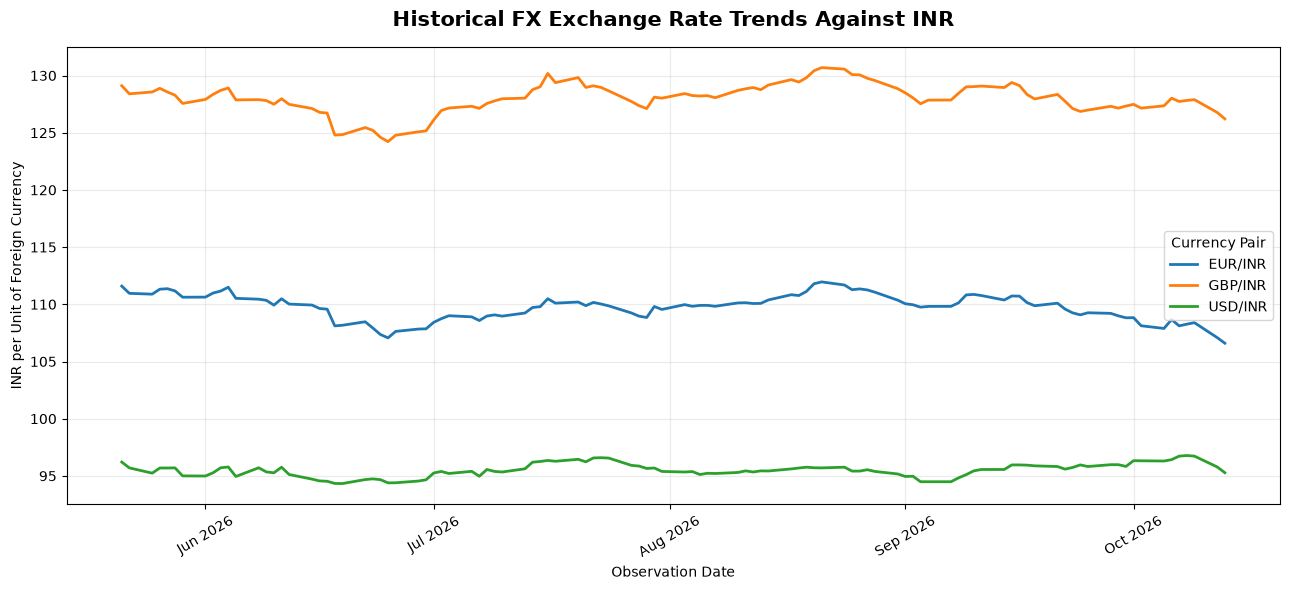

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\01_FX_Exchange_Rate_Trends.png


In [7]:

# ============================================================
# VISUALIZATION 1: ACTUAL FX EXCHANGE RATE TRENDS
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6))

for currency in fx_pivot.columns:
    ax.plot(
        fx_pivot.index,
        fx_pivot[currency],
        linewidth=2,
        label=currency
    )

ax.set_title(
    "Historical FX Exchange Rate Trends Against INR",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Observation Date")
ax.set_ylabel("INR per Unit of Foreign Currency")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.grid(alpha=0.25)
ax.legend(title="Currency Pair")

plt.xticks(rotation=30)
plt.tight_layout()

chart_path = (
    visualization_dir / "01_FX_Exchange_Rate_Trends.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", chart_path)


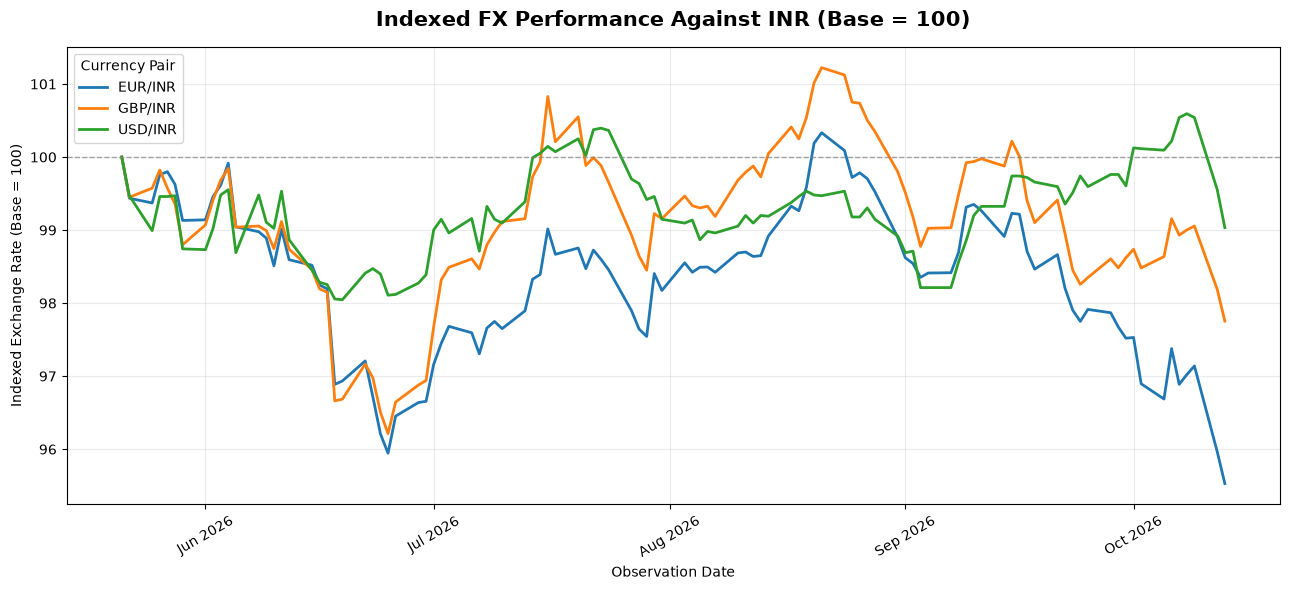

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\02_FX_Indexed_Performance.png

FX Percentage Change:
currency_pair
EUR/INR   -4.47
GBP/INR   -2.25
USD/INR   -0.97
Name: 2026-10-13 00:00:00, dtype: float64


In [8]:

# ============================================================
# VISUALIZATION 2: INDEXED FX PERFORMANCE
# ============================================================

# Normalize each currency to a starting value of 100
fx_indexed = (
    fx_pivot / fx_pivot.iloc[0]
) * 100

# Validate normalization
assert np.allclose(
    fx_indexed.iloc[0].to_numpy(),
    100
)

fig, ax = plt.subplots(figsize=(13, 6))

for currency in fx_indexed.columns:
    ax.plot(
        fx_indexed.index,
        fx_indexed[currency],
        linewidth=2,
        label=currency
    )

ax.axhline(
    y=100,
    linestyle="--",
    linewidth=1,
    color="gray",
    alpha=0.7
)

ax.set_title(
    "Indexed FX Performance Against INR (Base = 100)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Observation Date")
ax.set_ylabel("Indexed Exchange Rate (Base = 100)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.grid(alpha=0.25)
ax.legend(title="Currency Pair")

plt.xticks(rotation=30)
plt.tight_layout()

indexed_chart_path = (
    visualization_dir / "02_FX_Indexed_Performance.png"
)

plt.savefig(
    indexed_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", indexed_chart_path)

# Calculate final percentage changes
fx_percentage_change = (
    (fx_indexed.iloc[-1] / 100) - 1
) * 100

print("\nFX Percentage Change:")
print(fx_percentage_change.round(2))



### FX Trend Analysis — Business Findings

**Analysis Period:** May 21 – October 13, 2026

#### Key Findings

1. EUR/INR declined by approximately 4.47%, representing
   the largest overall exchange-rate decrease.

2. GBP/INR declined by approximately 2.25%.

3. USD/INR declined by approximately 0.97%, representing
   the smallest overall decrease.

4. All three foreign currencies weakened against INR
   between the opening and closing observations.

#### Business Implications

For an Indian importer with fixed foreign-currency
payment obligations, these movements would reduce
the INR amount required to settle those obligations
when comparing the first and last observation dates.

However, exchange rates fluctuated during the period,
so treasury teams should monitor daily movements
rather than relying only on overall percentage changes.


## 4. Daily FX Returns and Volatility Analysis

### Business Question
Which currency pair exhibits the highest historical
exchange-rate volatility against INR?

### Business Objective
Measure daily exchange-rate fluctuations to support
currency risk monitoring for an Indian import-payment
treasury team.

### Methodology
1. Calculate daily percentage returns using pct_change().
2. Calculate average daily percentage returns.
3. Calculate daily volatility using sample standard deviation.
4. Annualize volatility using the square root of 252.
5. Identify the largest daily increase and decrease.
6. Compare Python results with PostgreSQL calculations.
7. Create and save two financial risk visualizations.

### Business Interpretation
Positive daily returns indicate foreign-currency
appreciation against INR, potentially increasing
import-payment costs.

Negative daily returns indicate foreign-currency
depreciation against INR, potentially reducing
import-payment costs.

Higher historical volatility indicates greater
variability in exchange-rate movements.

### Important Assumptions
- Consecutive available observations are used.
- Non-trading days are not separately modeled.
- Outlier observations are retained.
- Annualization assumes 252 trading days.
- Historical volatility is not a forecast.


In [9]:

# ============================================================
# STEP 7.4: DAILY FX RETURNS
# ============================================================

# Calculate percentage changes between observations
fx_daily_returns = (
    fx_pivot.pct_change(fill_method=None) * 100
).dropna()

# Validate calculated returns
assert fx_daily_returns.shape == (103, 3)
assert fx_daily_returns.isna().sum().sum() == 0

print("Daily FX return calculation: PASSED")
print("FX return shape:", fx_daily_returns.shape)

print("\nFirst five daily return observations:")
display(fx_daily_returns.head())

print("\nDaily return descriptive statistics:")
display(fx_daily_returns.describe().round(4))


Daily FX return calculation: PASSED
FX return shape: (103, 3)

First five daily return observations:


currency_pair,EUR/INR,GBP/INR,USD/INR
observation_date,,,
2026-05-22,-0.564574,-0.549919,-0.530090
2026-05-25,-0.064439,0.124611,-0.480669
2026-05-26,0.390488,0.248911,0.472491
2026-05-27,0.040424,-0.248293,0.000000
2026-05-28,-0.174651,-0.217797,0.010450



Daily return descriptive statistics:


currency_pair,EUR/INR,GBP/INR,USD/INR
count,103.0000,103.0000,103.0000
mean,-0.0437,-0.0213,-0.0090
std,0.3713,0.3864,0.3104
min,-1.3315,-1.5152,-0.9821
25%,-0.2523,-0.2493,-0.1566
50%,-0.0622,0.0155,0.0000
75%,0.1974,0.2499,0.1363
max,0.8824,0.8991,0.8004


In [10]:

# ============================================================
# FX VOLATILITY METRICS
# ============================================================

fx_volatility_summary = pd.DataFrame({
    "avg_daily_return_pct": fx_daily_returns.mean(),
    "daily_volatility_pct": fx_daily_returns.std(ddof=1),
    "annualized_volatility_pct": (
        fx_daily_returns.std(ddof=1) * np.sqrt(252)
    ),
    "largest_daily_increase_pct": fx_daily_returns.max(),
    "largest_daily_decrease_pct": fx_daily_returns.min()
})

fx_volatility_summary.index.name = "currency_pair"

fx_volatility_summary = (
    fx_volatility_summary
    .sort_values(
        "annualized_volatility_pct",
        ascending=False
    )
)

print("FX Volatility Summary:")
display(fx_volatility_summary.round(4))

# Validate against PostgreSQL Step 6.3
expected_volatility = {
    "GBP/INR": 6.1332,
    "EUR/INR": 5.8938,
    "USD/INR": 4.9279
}

for currency, expected in expected_volatility.items():
    actual = fx_volatility_summary.loc[
        currency, "annualized_volatility_pct"
    ]

    assert np.isclose(
        actual,
        expected,
        atol=0.0001
    ), f"Volatility mismatch for {currency}"

print("\nPython vs PostgreSQL reconciliation: PASSED")


FX Volatility Summary:


,avg_daily_return_pct,daily_volatility_pct,annualized_volatility_pct,largest_daily_increase_pct,largest_daily_decrease_pct
currency_pair,,,,,
GBP/INR,-0.0213,0.3864,6.1332,0.8991,-1.5152
EUR/INR,-0.0437,0.3713,5.8938,0.8824,-1.3315
USD/INR,-0.0090,0.3104,4.9279,0.8004,-0.9821



Python vs PostgreSQL reconciliation: PASSED


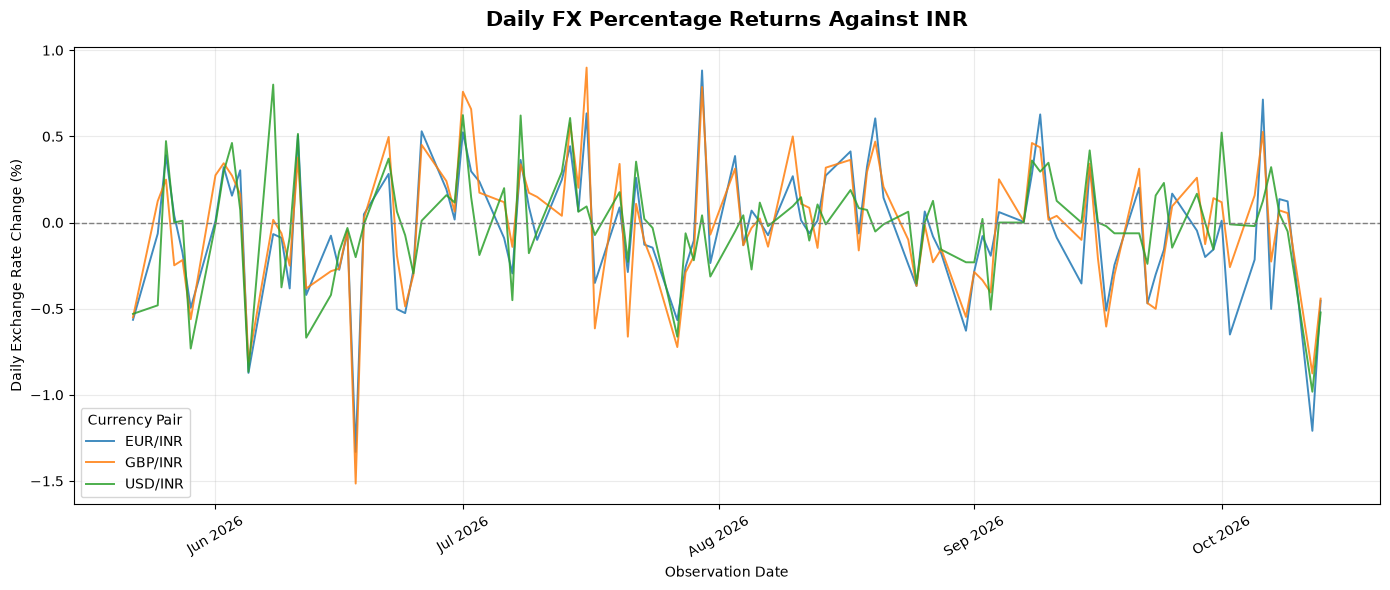

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\03_FX_Daily_Returns.png


In [11]:

# ============================================================
# VISUALIZATION 3: DAILY FX PERCENTAGE RETURNS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

for currency in fx_daily_returns.columns:
    ax.plot(
        fx_daily_returns.index,
        fx_daily_returns[currency],
        linewidth=1.4,
        alpha=0.85,
        label=currency
    )

ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Daily FX Percentage Returns Against INR",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Observation Date")
ax.set_ylabel("Daily Exchange Rate Change (%)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.legend(title="Currency Pair")
ax.grid(alpha=0.25)

plt.xticks(rotation=30)
plt.tight_layout()

daily_returns_chart_path = (
    visualization_dir / "03_FX_Daily_Returns.png"
)

plt.savefig(
    daily_returns_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", daily_returns_chart_path)


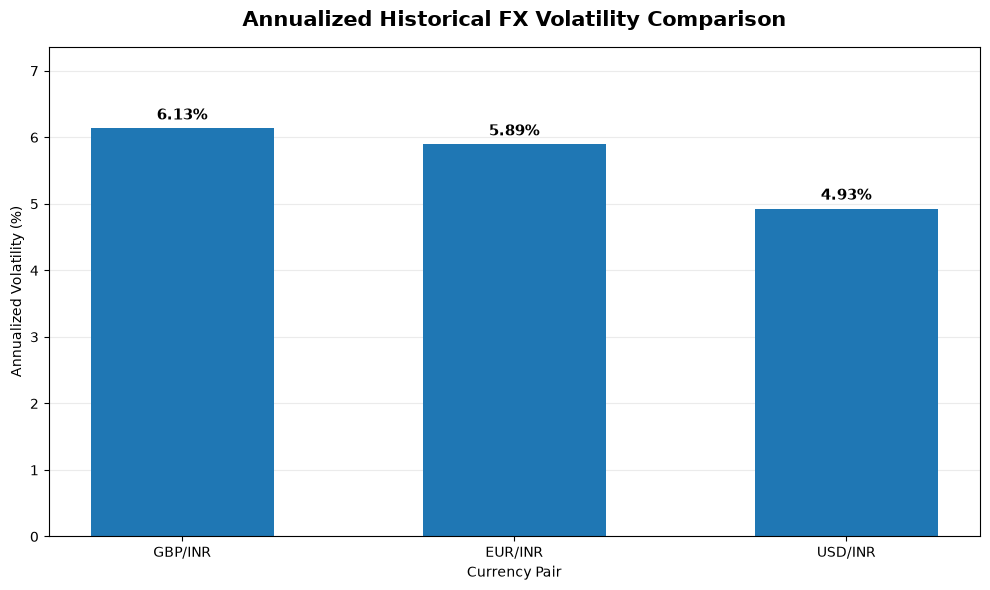

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\04_FX_Annualized_Volatility.png


In [12]:

# ============================================================
# VISUALIZATION 4: ANNUALIZED FX VOLATILITY
# ============================================================

volatility_values = (
    fx_volatility_summary["annualized_volatility_pct"]
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    volatility_values.index,
    volatility_values.values,
    width=0.55
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.08,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Annualized Historical FX Volatility Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Currency Pair")
ax.set_ylabel("Annualized Volatility (%)")

ax.set_ylim(
    0,
    volatility_values.max() * 1.2
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.set_axisbelow(True)

plt.tight_layout()

volatility_chart_path = (
    visualization_dir / "04_FX_Annualized_Volatility.png"
)

plt.savefig(
    volatility_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", volatility_chart_path)



### FX Daily Returns and Volatility — Business Findings

**Analysis Period:** May 21 – October 13, 2026

#### Historical Volatility Ranking

| Rank | Currency | Annualized Volatility |
|---|---|---:|
| 1 | GBP/INR | 6.1332% |
| 2 | EUR/INR | 5.8938% |
| 3 | USD/INR | 4.9279% |

#### Key Findings

1. GBP/INR recorded the highest daily and annualized
   volatility among the three currency pairs.

2. EUR/INR exhibited the second-highest volatility.

3. USD/INR demonstrated the lowest historical volatility.

4. Daily FX returns included both positive and negative
   movements, despite all three currencies declining
   between the opening and closing observations.

#### Business Implications

GBP-denominated import payments may require closer
monitoring because GBP/INR showed greater historical
exchange-rate variability.

However, treasury risk depends on both volatility and
the size and timing of outstanding foreign-currency
payments.

#### Limitations

- Historical volatility does not predict future volatility.
- Annualization uses a 252-trading-day convention.
- Observations may span weekends or market holidays.
- Outliers are retained in the calculations.
- Results do not account for hedging or transaction costs.


## 5. FX Import Payment Exposure and Stress Testing

### Business Question
How much additional INR would an Indian importer need
if foreign currencies appreciated against INR?

### Business Objective
Measure hypothetical foreign-currency import-payment
exposure and estimate the additional INR required
under adverse exchange-rate scenarios.

### Scenario Assumptions
- USD invoice: 100,000 USD
- EUR invoice: 100,000 EUR
- GBP invoice: 100,000 GBP
- Reference date: October 13, 2026
- Scenario 1: Foreign currencies appreciate by 2%
- Scenario 2: Foreign currencies appreciate by 5%

### Methodology
1. Extract the latest exchange rate for each currency.
2. Define illustrative foreign-currency invoices.
3. Convert invoices into INR exposure.
4. Calculate stressed INR costs.
5. Calculate additional payment requirements.
6. Reconcile calculations with PostgreSQL.
7. Visualize exposure distribution and stress impacts.

### Important
These are hypothetical invoice amounts and stress
scenarios, not actual transactions or forecasts.

The calculations assume unhedged exposure and exclude
transaction costs and existing forward contracts.


In [13]:

# ============================================================
# STEP 7.5: FX IMPORT PAYMENT EXPOSURE
# ============================================================

# Hypothetical foreign-currency invoices
import_invoices = pd.DataFrame({
    "currency": ["USD", "EUR", "GBP"],
    "invoice_amount": [100000, 100000, 100000]
})

# Retrieve latest validated exchange rates
latest_fx = (
    fx_analysis
    .sort_values("observation_date")
    .groupby("base_currency", as_index=False)
    .tail(1)
    [["base_currency", "observation_date", "exchange_rate"]]
    .rename(columns={
        "base_currency": "currency",
        "observation_date": "rate_date",
        "exchange_rate": "current_rate"
    })
)

# Merge invoices with latest FX rates
import_exposure = import_invoices.merge(
    latest_fx,
    on="currency",
    how="left",
    validate="one_to_one"
)

# Verify all invoices have exchange rates
assert import_exposure["current_rate"].notna().all()

# Calculate current INR exposure
import_exposure["current_inr_exposure"] = (
    import_exposure["invoice_amount"]
    * import_exposure["current_rate"]
)

# Calculate stressed payment requirements
for stress_pct in [2, 5]:

    import_exposure[
        f"stressed_inr_cost_{stress_pct}pct"
    ] = (
        import_exposure["current_inr_exposure"]
        * (1 + stress_pct / 100)
    )

    import_exposure[
        f"additional_cost_{stress_pct}pct"
    ] = (
        import_exposure["current_inr_exposure"]
        * (stress_pct / 100)
    )

import_exposure = (
    import_exposure
    .sort_values("currency")
    .reset_index(drop=True)
)

print("FX Import Exposure Analysis:")
display(import_exposure.round(2))


FX Import Exposure Analysis:


C:\Users\Dell\AppData\Local\Temp\ipykernel_26632\2605934744.py:66: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(import_exposure.round(2))


,currency,invoice_amount,rate_date,current_rate,current_inr_exposure,stressed_inr_cost_2pct,additional_cost_2pct,stressed_inr_cost_5pct,additional_cost_5pct
0,EUR,100000,2026-10-13,106.60,10660000.0,10873200.0,213200.0,11193000.0,533000.0
1,GBP,100000,2026-10-13,126.21,12621000.0,12873420.0,252420.0,13252050.0,631050.0
2,USD,100000,2026-10-13,95.28,9528000.0,9718560.0,190560.0,10004400.0,476400.0


In [14]:

# ============================================================
# VALIDATION: PYTHON VS POSTGRESQL
# ============================================================

expected_exposure = {
    "EUR": {
        "current": 10660000,
        "stress_2": 213200,
        "stress_5": 533000
    },
    "GBP": {
        "current": 12621000,
        "stress_2": 252420,
        "stress_5": 631050
    },
    "USD": {
        "current": 9528000,
        "stress_2": 190560,
        "stress_5": 476400
    }
}

for _, row in import_exposure.iterrows():

    expected = expected_exposure[row["currency"]]

    assert np.isclose(
        row["current_inr_exposure"],
        expected["current"],
        atol=0.01
    )

    assert np.isclose(
        row["additional_cost_2pct"],
        expected["stress_2"],
        atol=0.01
    )

    assert np.isclose(
        row["additional_cost_5pct"],
        expected["stress_5"],
        atol=0.01
    )

# Portfolio-level calculations
portfolio_summary = {
    "total_current_exposure":
        import_exposure["current_inr_exposure"].sum(),

    "total_additional_cost_2pct":
        import_exposure["additional_cost_2pct"].sum(),

    "total_additional_cost_5pct":
        import_exposure["additional_cost_5pct"].sum()
}

assert np.isclose(
    portfolio_summary["total_current_exposure"],
    32809000,
    atol=0.01
)

assert np.isclose(
    portfolio_summary["total_additional_cost_2pct"],
    656180,
    atol=0.01
)

assert np.isclose(
    portfolio_summary["total_additional_cost_5pct"],
    1640450,
    atol=0.01
)

print("Python vs PostgreSQL reconciliation: PASSED")

for metric, value in portfolio_summary.items():
    print(f"{metric}: INR {value:,.2f}")


Python vs PostgreSQL reconciliation: PASSED
total_current_exposure: INR 32,809,000.00
total_additional_cost_2pct: INR 656,180.00
total_additional_cost_5pct: INR 1,640,450.00


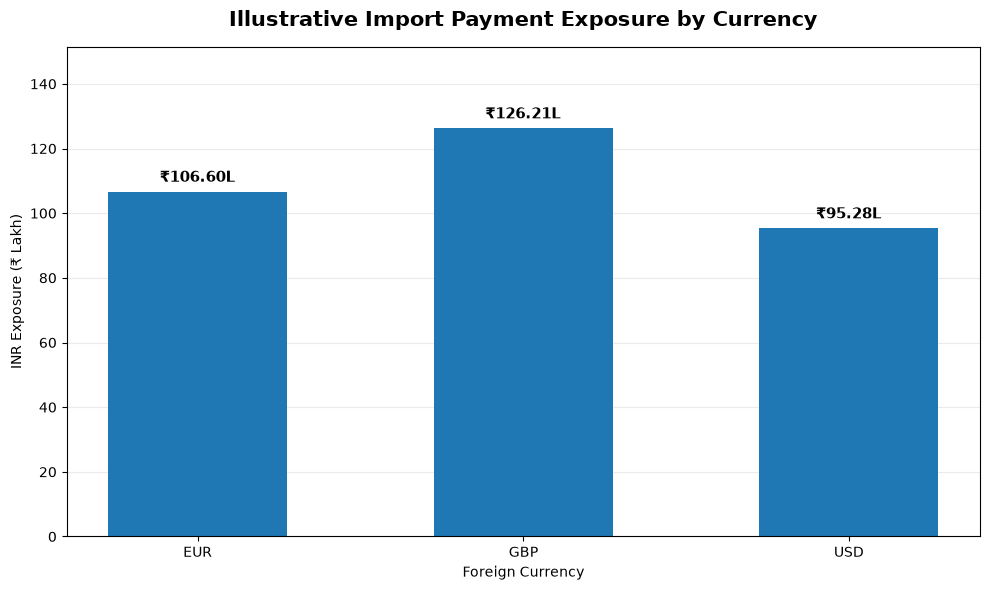

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\05_FX_Import_Exposure.png


In [15]:

# ============================================================
# VISUALIZATION 5: FX IMPORT EXPOSURE DISTRIBUTION
# ============================================================

exposure_values = (
    import_exposure["current_inr_exposure"] / 100000
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    import_exposure["currency"],
    exposure_values,
    width=0.55
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"₹{height:.2f}L",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Illustrative Import Payment Exposure by Currency",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Foreign Currency")
ax.set_ylabel("INR Exposure (₹ Lakh)")

ax.set_ylim(
    0,
    exposure_values.max() * 1.2
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

exposure_chart_path = (
    visualization_dir / "05_FX_Import_Exposure.png"
)

plt.savefig(
    exposure_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", exposure_chart_path)


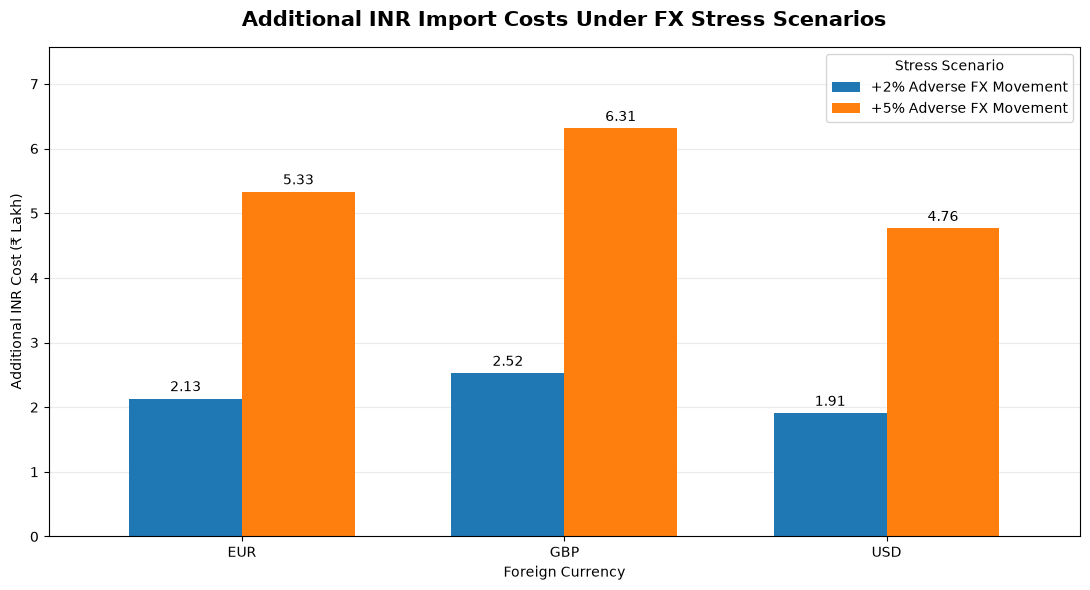

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\06_FX_Stress_Scenarios.png


In [16]:

# ============================================================
# VISUALIZATION 6: FX STRESS SCENARIO COMPARISON
# ============================================================

stress_chart_data = import_exposure.set_index("currency")[
    [
        "additional_cost_2pct",
        "additional_cost_5pct"
    ]
] / 100000

stress_chart_data.columns = [
    "+2% Adverse FX Movement",
    "+5% Adverse FX Movement"
]

ax = stress_chart_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.7
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=10
    )

ax.set_title(
    "Additional INR Import Costs Under FX Stress Scenarios",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Foreign Currency")
ax.set_ylabel("Additional INR Cost (₹ Lakh)")

ax.set_ylim(
    0,
    stress_chart_data.to_numpy().max() * 1.2
)

ax.legend(title="Stress Scenario")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()

stress_chart_path = (
    visualization_dir / "06_FX_Stress_Scenarios.png"
)

plt.savefig(
    stress_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", stress_chart_path)



### FX Import Exposure and Stress Testing — Business Findings

#### Scenario
Hypothetical invoices of 100,000 units each in USD,
EUR, and GBP, valued using October 13, 2026 FX rates.

#### Current INR Exposure
- GBP: ₹1,26,21,000
- EUR: ₹1,06,60,000
- USD: ₹95,28,000
- Total: ₹3,28,09,000

#### Adverse FX Scenario Results

| Scenario | Additional INR Required |
|---|---:|
| +2% FX appreciation | ₹6,56,180 |
| +5% FX appreciation | ₹16,40,450 |

#### Key Findings
1. GBP represents the largest INR payment exposure
   in the illustrative portfolio.

2. A uniform 2% foreign-currency appreciation would
   increase the combined INR payment requirement
   by ₹6.56 lakh.

3. A uniform 5% foreign-currency appreciation would
   increase the combined INR payment requirement
   by ₹16.40 lakh.

4. GBP produces the largest absolute increase in INR
   payment cost under both stress scenarios.

#### Treasury Recommendations
- Monitor outstanding foreign-currency payment amounts.
- Track invoice settlement dates.
- Use stress scenarios to plan INR cash requirements.
- Evaluate hedging options under company treasury policy.
- Refresh FX rates before making payment decisions.

#### Limitations
These results are illustrative and do not represent
realized losses, actual company invoices, or forecasts.

The scenarios assume unhedged exposure and exclude
transaction costs and existing hedging arrangements.



## 6. Banking Stock Price Trends and Indexed Performance

### Business Question
How did HDFC Bank, ICICI Bank, and State Bank of India
perform during the historical analysis period?

### Business Objective
Compare the closing-price movements and historical
price returns of three major Indian banking stocks.

### Data Source
Validated PostgreSQL banking_stocks table.

### Analysis Period
May 22, 2026 – October 13, 2026

### Methodology
1. Retrieve the validated banking stock DataFrame.
2. Prepare a closing-price time series.
3. Verify date alignment across all three stocks.
4. Calculate opening and closing price returns.
5. Visualize actual closing-price trends.
6. Normalize each stock to a starting index of 100.
7. Compare Python results with PostgreSQL analysis.

### Business Interpretation
Actual closing-price charts show each stock's price level.

Indexed performance charts allow a fairer comparison
of relative percentage movements because each stock
starts at the same index value.

### Limitations
- Price returns exclude dividends and transaction costs.
- Historical performance does not predict future returns.
- This is market intelligence, not investment advice.


In [17]:

# ============================================================
# STEP 7.6: BANKING STOCK PRICE ANALYSIS
# ============================================================

# Create a separate analytical DataFrame
stocks_analysis = stocks_df.copy()

# Ensure date and price types are correct
stocks_analysis["observation_date"] = pd.to_datetime(
    stocks_analysis["observation_date"]
)

stocks_analysis["close_price"] = pd.to_numeric(
    stocks_analysis["close_price"],
    errors="raise"
)

# Prepare closing-price time series
stock_price_pivot = stocks_analysis.pivot(
    index="observation_date",
    columns="stock_symbol",
    values="close_price"
).sort_index()

# Validate expected instruments
expected_stocks = {
    "HDFCBANK.BSE",
    "ICICIBANK.BSE",
    "SBIN.BSE"
}

assert set(stock_price_pivot.columns) == expected_stocks

# Validate time-series dimensions and completeness
assert stock_price_pivot.shape == (99, 3)
assert stock_price_pivot.isna().sum().sum() == 0
assert (stock_price_pivot > 0).all().all()

print("Banking stock time-series preparation: PASSED")
print("Stock price pivot shape:", stock_price_pivot.shape)
print("Stock symbols:", stock_price_pivot.columns.tolist())

print("\nDate coverage:")
print(
    stock_price_pivot.index.min().date(),
    "to",
    stock_price_pivot.index.max().date()
)

print("\nFirst five observations:")
display(stock_price_pivot.head())


Banking stock time-series preparation: PASSED
Stock price pivot shape: (99, 3)
Stock symbols: ['HDFCBANK.BSE', 'ICICIBANK.BSE', 'SBIN.BSE']

Date coverage:
2026-05-22 to 2026-10-13

First five observations:


stock_symbol,HDFCBANK.BSE,ICICIBANK.BSE,SBIN.BSE
observation_date,,,
2026-05-22,766.40,1264.90,949.10
2026-05-25,786.85,1291.60,969.90
2026-05-26,779.00,1279.15,968.60
2026-05-27,758.50,1272.80,967.65
2026-05-29,744.75,1256.00,964.00


In [18]:

# ============================================================
# BANKING STOCK HISTORICAL PRICE PERFORMANCE
# ============================================================

stock_performance = pd.DataFrame({
    "opening_close_price": stock_price_pivot.iloc[0],
    "latest_close_price": stock_price_pivot.iloc[-1],
    "minimum_close_price": stock_price_pivot.min(),
    "maximum_close_price": stock_price_pivot.max(),
    "average_close_price": stock_price_pivot.mean()
})

# Absolute price change
stock_performance["price_change"] = (
    stock_performance["latest_close_price"]
    - stock_performance["opening_close_price"]
)

# Historical price return
stock_performance["price_return_pct"] = (
    stock_performance["price_change"]
    / stock_performance["opening_close_price"]
) * 100

stock_performance.index.name = "stock_symbol"

stock_performance = stock_performance.sort_values(
    "price_return_pct",
    ascending=False
)

print("Banking Stock Historical Performance:")
display(stock_performance.round(2))

# Reconcile with PostgreSQL Step 6.7
expected_returns = {
    "ICICIBANK.BSE": 7.53,
    "SBIN.BSE": 0.72,
    "HDFCBANK.BSE": -6.81
}

for symbol, expected in expected_returns.items():

    actual = stock_performance.loc[
        symbol, "price_return_pct"
    ]

    assert np.isclose(
        actual,
        expected,
        atol=0.01
    ), f"Price return mismatch: {symbol}"

print("\nPython vs PostgreSQL reconciliation: PASSED")


Banking Stock Historical Performance:


,opening_close_price,latest_close_price,minimum_close_price,maximum_close_price,average_close_price,price_change,price_return_pct
stock_symbol,,,,,,,
ICICIBANK.BSE,1264.9,1360.2,1226.35,1476.95,1374.68,95.3,7.53
SBIN.BSE,949.1,955.9,940.65,1096.05,1014.31,6.8,0.72
HDFCBANK.BSE,766.4,714.2,687.25,829.75,748.26,-52.2,-6.81



Python vs PostgreSQL reconciliation: PASSED


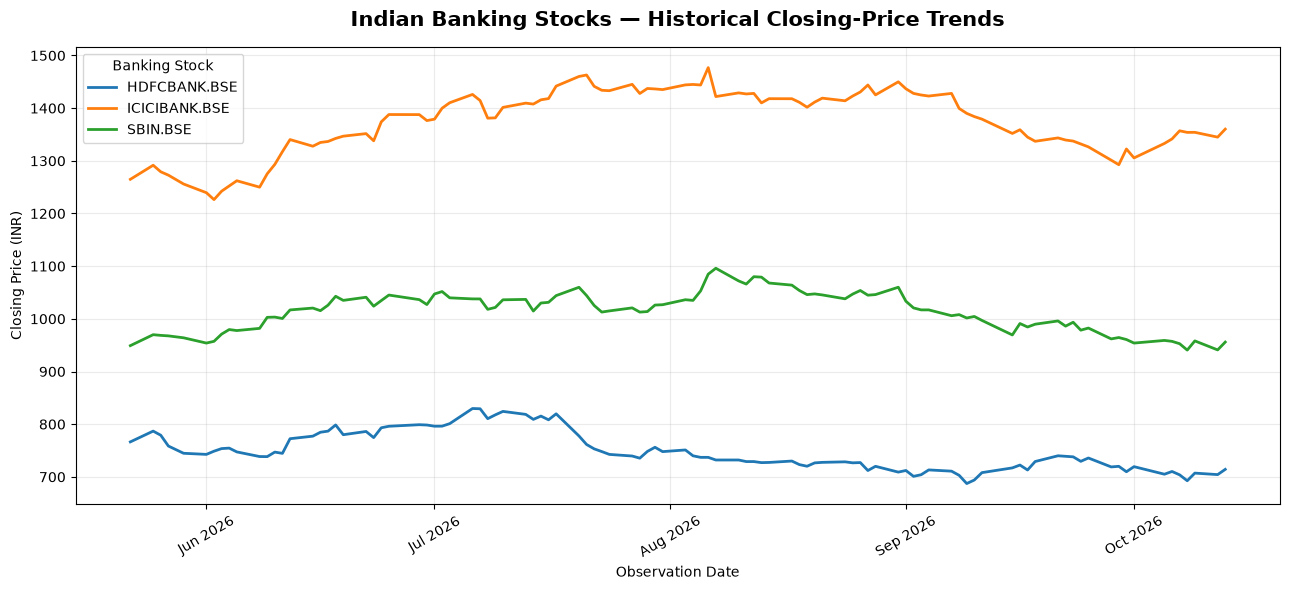

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\07_Banking_Stock_Price_Trends.png


In [19]:

# ============================================================
# VISUALIZATION 7: BANKING STOCK CLOSING-PRICE TRENDS
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6))

for stock in stock_price_pivot.columns:

    ax.plot(
        stock_price_pivot.index,
        stock_price_pivot[stock],
        linewidth=2,
        label=stock
    )

ax.set_title(
    "Indian Banking Stocks — Historical Closing-Price Trends",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Observation Date")
ax.set_ylabel("Closing Price (INR)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.grid(alpha=0.25)
ax.legend(title="Banking Stock")

plt.xticks(rotation=30)
plt.tight_layout()

stock_price_chart_path = (
    visualization_dir / "07_Banking_Stock_Price_Trends.png"
)

plt.savefig(
    stock_price_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", stock_price_chart_path)


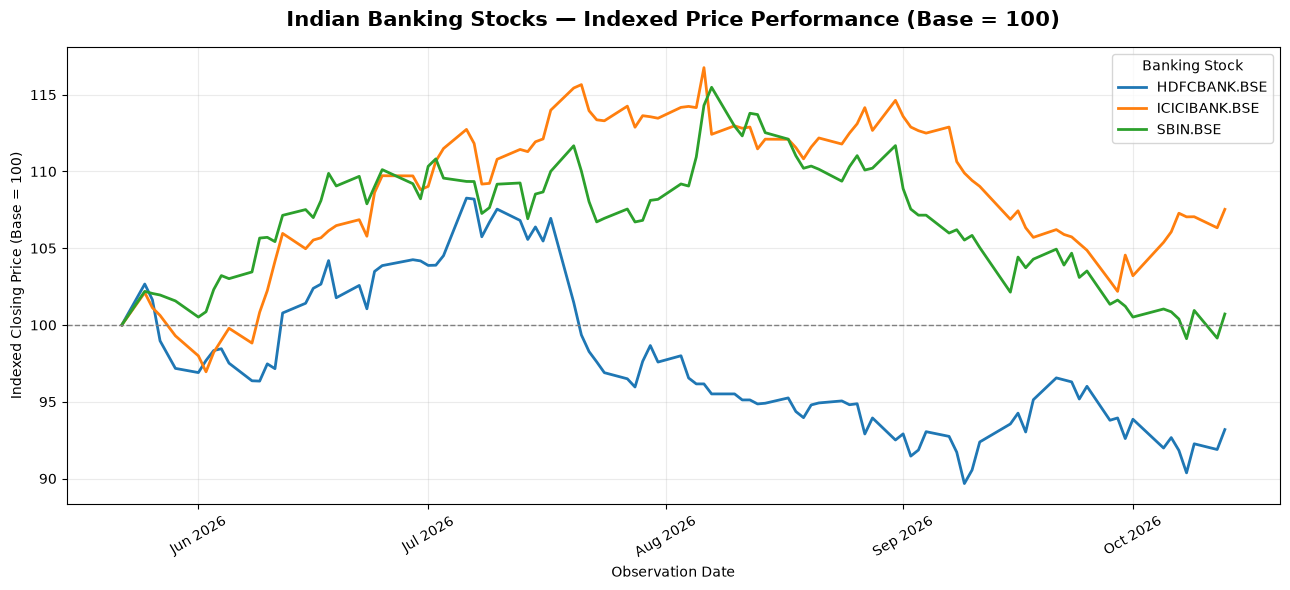

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\08_Banking_Stock_Indexed_Performance.png

Final Indexed Stock Returns:
stock_symbol
HDFCBANK.BSE    -6.81
ICICIBANK.BSE    7.53
SBIN.BSE         0.72
Name: 2026-10-13 00:00:00, dtype: float64


In [20]:

# ============================================================
# VISUALIZATION 8: INDEXED BANKING STOCK PERFORMANCE
# ============================================================

# Normalize stock prices to a starting index of 100
stock_indexed = (
    stock_price_pivot / stock_price_pivot.iloc[0]
) * 100

# Validate normalization
assert np.allclose(
    stock_indexed.iloc[0].to_numpy(),
    100
)

fig, ax = plt.subplots(figsize=(13, 6))

for stock in stock_indexed.columns:

    ax.plot(
        stock_indexed.index,
        stock_indexed[stock],
        linewidth=2,
        label=stock
    )

ax.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Indian Banking Stocks — Indexed Price Performance (Base = 100)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Observation Date")
ax.set_ylabel("Indexed Closing Price (Base = 100)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.grid(alpha=0.25)
ax.legend(title="Banking Stock")

plt.xticks(rotation=30)
plt.tight_layout()

indexed_stock_chart_path = (
    visualization_dir / "08_Banking_Stock_Indexed_Performance.png"
)

plt.savefig(
    indexed_stock_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", indexed_stock_chart_path)

# Final indexed percentage returns
indexed_stock_returns = (
    stock_indexed.iloc[-1] - 100
)

print("\nFinal Indexed Stock Returns:")
print(indexed_stock_returns.round(2))



### Banking Stock Price Trends — Business Findings

**Analysis Period:** May 22 – October 13, 2026

#### Historical Price Performance

| Stock | Price Return |
|---|---:|
| ICICI Bank | +7.53% |
| State Bank of India | +0.72% |
| HDFC Bank | -6.81% |

#### Key Findings

1. ICICI Bank delivered the strongest historical
   closing-price return at approximately +7.53%.

2. State Bank of India recorded a modest positive
   price return of approximately +0.72%.

3. HDFC Bank experienced a negative price return
   of approximately -6.81%.

4. Indexed performance makes the relative movements
   of the three stocks directly comparable.

#### Business Implications

The three banking stocks showed different price
trajectories during the same observation period.

This supports further analysis of:
- Daily returns and volatility.
- Trading volume and unusual volume observations.
- Correlations between banking stock returns.
- Historical risk-adjusted performance measures.

#### Limitations

- Returns exclude dividends and transaction costs.
- The observation window is relatively short.
- Price performance alone does not measure investment risk.
- Results do not represent investment recommendations.


## 7. Banking Stock Daily Returns and Volatility Analysis

### Business Question
Which Indian banking stock demonstrated the highest
historical price volatility?

### Business Objective
Compare daily closing-price returns and historical
volatility across HDFC Bank, ICICI Bank, and SBI.

### Methodology
1. Calculate daily closing-price percentage returns.
2. Calculate average daily returns.
3. Calculate daily return standard deviation.
4. Annualize volatility using sqrt(252).
5. Identify the largest daily gains and losses.
6. Reconcile Python results with PostgreSQL.
7. Visualize daily returns and annualized volatility.

### Calculation

Daily Return (%) =
(Current Closing Price / Previous Closing Price - 1) * 100

Daily Volatility (%) =
Sample Standard Deviation of Daily Returns

Annualized Volatility (%) =
Daily Volatility * sqrt(252)

### Business Interpretation
Higher volatility indicates greater historical variability
in daily stock returns.

Volatility measures the magnitude of fluctuations,
not whether the stock is a good or bad investment.

### Assumptions and Limitations
- Calculations use closing prices.
- Daily returns use consecutive available trading dates.
- Annualization assumes 252 trading days.
- Sample standard deviation uses ddof=1.
- Previously flagged observations remain included.
- Returns exclude dividends and transaction costs.


In [21]:

# ============================================================
# STEP 7.7: BANKING STOCK DAILY RETURNS
# ============================================================

# Calculate daily closing-price percentage returns
stock_daily_returns = (
    stock_price_pivot.pct_change(fill_method=None) * 100
).dropna()

# Validate expected dimensions
assert stock_daily_returns.shape == (98, 3)

# Validate completeness
assert stock_daily_returns.isna().sum().sum() == 0

# Confirm all three stocks are included
assert set(stock_daily_returns.columns) == {
    "HDFCBANK.BSE",
    "ICICIBANK.BSE",
    "SBIN.BSE"
}

print("Banking stock daily return calculation: PASSED")

print("\nDaily return DataFrame shape:")
print(stock_daily_returns.shape)

print("\nFirst five observations:")
display(stock_daily_returns.head())

print("\nDaily return descriptive statistics:")
display(stock_daily_returns.describe().round(4))


Banking stock daily return calculation: PASSED

Daily return DataFrame shape:
(98, 3)

First five observations:


stock_symbol,HDFCBANK.BSE,ICICIBANK.BSE,SBIN.BSE
observation_date,,,
2026-05-25,2.668319,2.110839,2.191550
2026-05-26,-0.997649,-0.963921,-0.134034
2026-05-27,-2.631579,-0.496423,-0.098080
2026-05-29,-1.812788,-1.319925,-0.377203
2026-06-01,-0.281974,-1.313694,-1.037344



Daily return descriptive statistics:


stock_symbol,HDFCBANK.BSE,ICICIBANK.BSE,SBIN.BSE
count,98.0000,98.0000,98.0000
mean,-0.0625,0.0803,0.0140
std,1.3787,1.1173,1.1630
min,-5.1241,-3.7205,-2.7683
25%,-0.9485,-0.6448,-0.7476
50%,-0.0102,0.0254,0.0224
75%,0.7979,0.6853,0.8366
max,3.7335,2.6867,3.0247


In [22]:

# ============================================================
# BANKING STOCK VOLATILITY METRICS
# ============================================================

stock_volatility_summary = pd.DataFrame({
    "avg_daily_return_pct":
        stock_daily_returns.mean(),

    "daily_volatility_pct":
        stock_daily_returns.std(ddof=1),

    "annualized_volatility_pct":
        stock_daily_returns.std(ddof=1) * np.sqrt(252),

    "largest_daily_gain_pct":
        stock_daily_returns.max(),

    "largest_daily_loss_pct":
        stock_daily_returns.min()
})

stock_volatility_summary.index.name = "stock_symbol"

stock_volatility_summary = (
    stock_volatility_summary
    .sort_values(
        "annualized_volatility_pct",
        ascending=False
    )
)

print("Banking Stock Volatility Summary:")
display(stock_volatility_summary.round(4))


Banking Stock Volatility Summary:


,avg_daily_return_pct,daily_volatility_pct,annualized_volatility_pct,largest_daily_gain_pct,largest_daily_loss_pct
stock_symbol,,,,,
HDFCBANK.BSE,-0.0625,1.3787,21.8859,3.7335,-5.1241
SBIN.BSE,0.0140,1.1630,18.4617,3.0247,-2.7683
ICICIBANK.BSE,0.0803,1.1173,17.7367,2.6867,-3.7205


In [23]:

# ============================================================
# VALIDATION: PYTHON VS POSTGRESQL
# ============================================================

expected_metrics = {
    "HDFCBANK.BSE": {
        "avg_daily_return_pct": -0.0625,
        "daily_volatility_pct": 1.3787,
        "annualized_volatility_pct": 21.8859,
        "largest_daily_gain_pct": 3.7335,
        "largest_daily_loss_pct": -5.1241
    },

    "SBIN.BSE": {
        "avg_daily_return_pct": 0.0140,
        "daily_volatility_pct": 1.1630,
        "annualized_volatility_pct": 18.4617,
        "largest_daily_gain_pct": 3.0247,
        "largest_daily_loss_pct": -2.7683
    },

    "ICICIBANK.BSE": {
        "avg_daily_return_pct": 0.0803,
        "daily_volatility_pct": 1.1173,
        "annualized_volatility_pct": 17.7367,
        "largest_daily_gain_pct": 2.6867,
        "largest_daily_loss_pct": -3.7205
    }
}

for stock, metrics in expected_metrics.items():

    for metric, expected_value in metrics.items():

        actual_value = stock_volatility_summary.loc[
            stock, metric
        ]

        assert np.isclose(
            actual_value,
            expected_value,
            atol=0.0001
        ), (
            f"Mismatch for {stock}, {metric}: "
            f"Python={actual_value:.6f}, "
            f"SQL={expected_value:.4f}"
        )

print("Python vs PostgreSQL reconciliation: PASSED")
print("All banking stock volatility metrics match SQL.")


Python vs PostgreSQL reconciliation: PASSED
All banking stock volatility metrics match SQL.


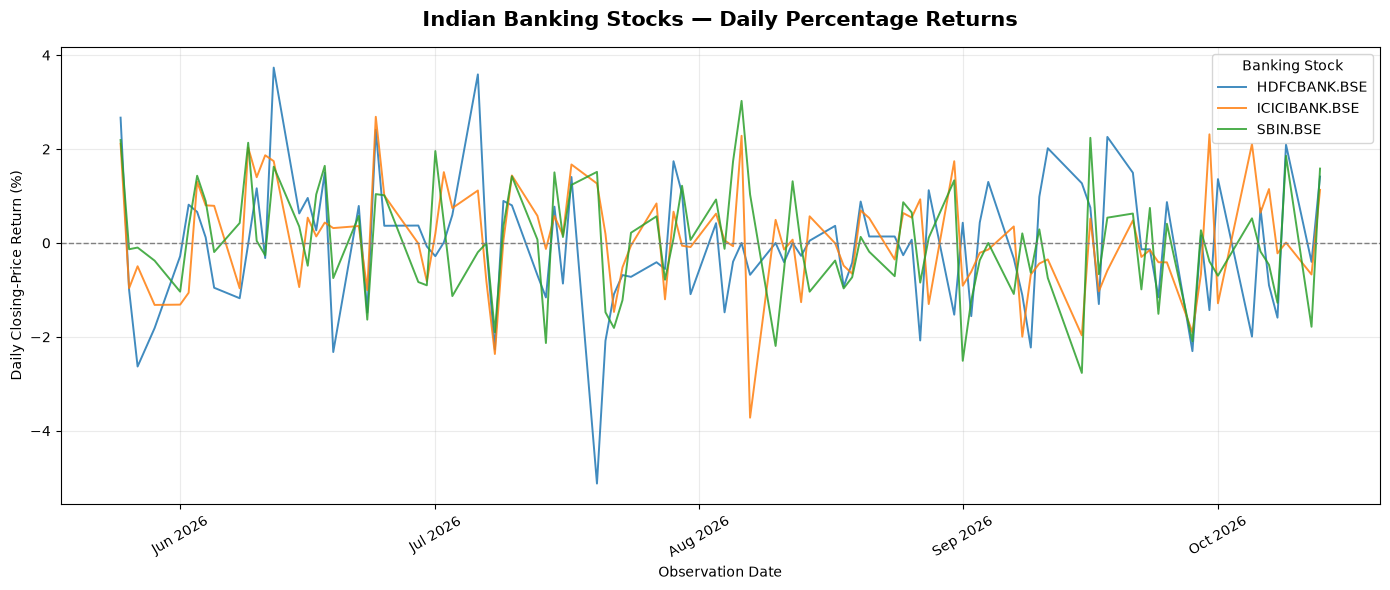

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\09_Banking_Stock_Daily_Returns.png


In [24]:

# ============================================================
# VISUALIZATION 9: BANKING STOCK DAILY RETURNS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

for stock in stock_daily_returns.columns:

    ax.plot(
        stock_daily_returns.index,
        stock_daily_returns[stock],
        linewidth=1.4,
        alpha=0.85,
        label=stock
    )

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Indian Banking Stocks — Daily Percentage Returns",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Observation Date")
ax.set_ylabel("Daily Closing-Price Return (%)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.legend(title="Banking Stock")
ax.grid(alpha=0.25)

plt.xticks(rotation=30)
plt.tight_layout()

stock_returns_chart_path = (
    visualization_dir / "09_Banking_Stock_Daily_Returns.png"
)

plt.savefig(
    stock_returns_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", stock_returns_chart_path)


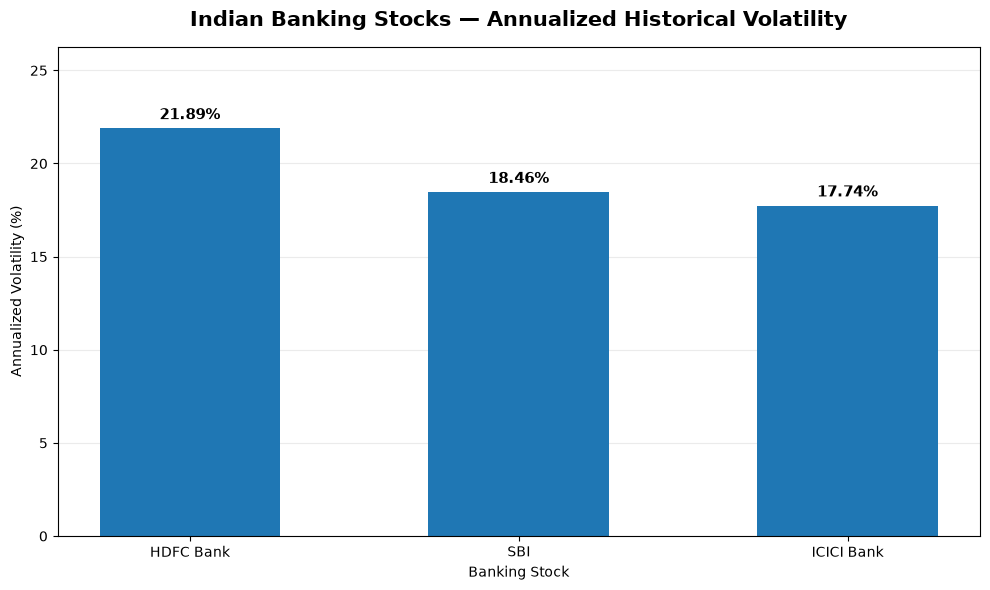

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\10_Banking_Stock_Annualized_Volatility.png


In [25]:

# ============================================================
# VISUALIZATION 10: ANNUALIZED STOCK VOLATILITY
# ============================================================

volatility_values = (
    stock_volatility_summary["annualized_volatility_pct"]
)

stock_labels = {
    "HDFCBANK.BSE": "HDFC Bank",
    "ICICIBANK.BSE": "ICICI Bank",
    "SBIN.BSE": "SBI"
}

display_labels = [
    stock_labels[symbol]
    for symbol in volatility_values.index
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    display_labels,
    volatility_values.values,
    width=0.55
)

for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Indian Banking Stocks — Annualized Historical Volatility",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Banking Stock")
ax.set_ylabel("Annualized Volatility (%)")

ax.set_ylim(
    0,
    volatility_values.max() * 1.2
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.set_axisbelow(True)

plt.tight_layout()

stock_volatility_chart_path = (
    visualization_dir / "10_Banking_Stock_Annualized_Volatility.png"
)

plt.savefig(
    stock_volatility_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", stock_volatility_chart_path)



### Banking Stock Returns and Volatility — Business Findings

**Analysis Period:** May 22 – October 13, 2026

#### Historical Volatility Ranking

| Rank | Banking Stock | Annualized Volatility |
|---|---|---:|
| 1 | HDFC Bank | 21.8859% |
| 2 | SBI | 18.4617% |
| 3 | ICICI Bank | 17.7367% |

#### Key Findings

1. HDFC Bank demonstrated the highest historical
   annualized volatility at approximately 21.89%.

2. SBI recorded the second-highest volatility
   at approximately 18.46%.

3. ICICI Bank had the lowest historical volatility
   at approximately 17.74%.

4. HDFC Bank also experienced the largest single-day
   loss among the three stocks at approximately -5.12%.

5. ICICI Bank recorded the highest average daily
   closing-price return during the analysis period.

#### Business Implications

The results demonstrate that banking stocks can exhibit
different return and risk characteristics even when
operating in the same industry.

HDFC Bank had both the highest historical volatility
and a negative overall price return during this period.

ICICI Bank combined the highest historical price return
with the lowest volatility among the three stocks.

#### Recommendations

- Monitor stock volatility alongside price returns.
- Investigate unusually large daily price movements.
- Compare volatility across common observation periods.
- Use correlation analysis to understand co-movement.
- Avoid interpreting historical returns as forecasts.

#### Limitations

- Historical volatility does not predict future volatility.
- The sample covers a relatively short period.
- Annualization assumes 252 trading days.
- Returns exclude dividends and transaction costs.
- The analysis is descriptive, not investment advice.



## 8. Banking Stock Trading Volume and Outlier Analysis

### Business Question
How does trading activity vary across HDFC Bank,
ICICI Bank, and SBI, and where do unusual trading
volumes occur?

### Business Objective
Analyze historical trading volumes and investigate
previously flagged statistical outliers.

### Methodology
1. Use the validated banking stock DataFrame.
2. Calculate average, minimum, maximum, and total volume.
3. Count previously flagged volume outliers.
4. Reconcile metrics with PostgreSQL.
5. Visualize daily volume and flagged observations.
6. Compare average daily volume across stocks.

### Outlier Handling
Volume outliers were previously identified during
data validation using the IQR method.

This analysis preserves the existing outlier flags.
No observations will be removed or reclassified.

### Business Interpretation
High trading volume indicates greater reported trading
activity during an observation.

Unusual volume may coincide with news, earnings,
market events, or other factors, but its cause cannot
be determined from volume data alone.

### Limitations
- Statistical outliers are not confirmed anomalies.
- Trading volume alone does not measure liquidity.
- Stock volumes are compared as reported share counts.
- Differences in shares outstanding and trading
  characteristics affect cross-stock comparisons.


In [26]:

# ============================================================
# STEP 7.8: BANKING STOCK TRADING VOLUME ANALYSIS
# ============================================================

volume_analysis = stocks_analysis.copy()

# Ensure numeric volume
volume_analysis["volume"] = pd.to_numeric(
    volume_analysis["volume"],
    errors="raise"
)

# Preserve previously validated outlier flags
volume_analysis["volume_outlier"] = (
    volume_analysis["volume_outlier"].astype(bool)
)

# Sort observations
volume_analysis = volume_analysis.sort_values(
    ["stock_symbol", "observation_date"]
).reset_index(drop=True)

# Validate data
assert len(volume_analysis) == 297
assert volume_analysis["volume"].notna().all()
assert (volume_analysis["volume"] >= 0).all()

assert volume_analysis["volume_outlier"].sum() == 21

print("Trading volume data preparation: PASSED")
print("Total observations:", len(volume_analysis))
print(
    "Flagged volume outliers:",
    volume_analysis["volume_outlier"].sum()
)

display(
    volume_analysis[
        [
            "observation_date",
            "stock_symbol",
            "volume",
            "volume_outlier"
        ]
    ].head()
)


Trading volume data preparation: PASSED
Total observations: 297
Flagged volume outliers: 21


,observation_date,stock_symbol,volume,volume_outlier
0,2026-05-22,HDFCBANK.BSE,629420,False
1,2026-05-25,HDFCBANK.BSE,964192,False
2,2026-05-26,HDFCBANK.BSE,932064,False
3,2026-05-27,HDFCBANK.BSE,4893862,False
4,2026-05-29,HDFCBANK.BSE,1799471,False


In [27]:

# ============================================================
# BANKING STOCK TRADING VOLUME METRICS
# ============================================================

volume_summary = volume_analysis.groupby(
    "stock_symbol"
).agg(
    observations=("volume", "size"),
    total_volume=("volume", "sum"),
    avg_daily_volume=("volume", "mean"),
    minimum_volume=("volume", "min"),
    maximum_volume=("volume", "max"),
    volume_outliers=("volume_outlier", "sum")
)

# Calculate percentage of flagged observations
volume_summary["outlier_rate_pct"] = (
    volume_summary["volume_outliers"]
    / volume_summary["observations"]
) * 100

volume_summary = volume_summary.sort_values(
    "avg_daily_volume",
    ascending=False
)

print("Banking Stock Trading Volume Summary:")
display(volume_summary.round(2))


Banking Stock Trading Volume Summary:


,observations,total_volume,avg_daily_volume,minimum_volume,maximum_volume,volume_outliers,outlier_rate_pct
stock_symbol,,,,,,,
HDFCBANK.BSE,99,207894787,2099947.34,427263,8163779,2,2.02
ICICIBANK.BSE,99,93793998,947414.12,53446,22674495,10,10.10
SBIN.BSE,99,69476314,701780.95,166447,2929881,9,9.09


In [28]:

# ============================================================
# VALIDATION: PYTHON VS POSTGRESQL
# ============================================================

expected_volume_metrics = {
    "HDFCBANK.BSE": {
        "total_volume": 207894787,
        "volume_outliers": 2,
        "avg_daily_volume": 2099947.34
    },
    "ICICIBANK.BSE": {
        "total_volume": 93793998,
        "volume_outliers": 10,
        "avg_daily_volume": 947414.12
    },
    "SBIN.BSE": {
        "total_volume": 69476314,
        "volume_outliers": 9,
        "avg_daily_volume": 701780.95
    }
}

for stock, metrics in expected_volume_metrics.items():

    for metric, expected in metrics.items():

        actual = volume_summary.loc[stock, metric]

        assert np.isclose(
            actual,
            expected,
            atol=0.01
        ), (
            f"Mismatch: {stock} | {metric} | "
            f"Python={actual} | SQL={expected}"
        )

assert volume_summary["observations"].eq(99).all()

print("Python vs PostgreSQL reconciliation: PASSED")
print("All banking stock volume metrics match SQL.")


Python vs PostgreSQL reconciliation: PASSED
All banking stock volume metrics match SQL.


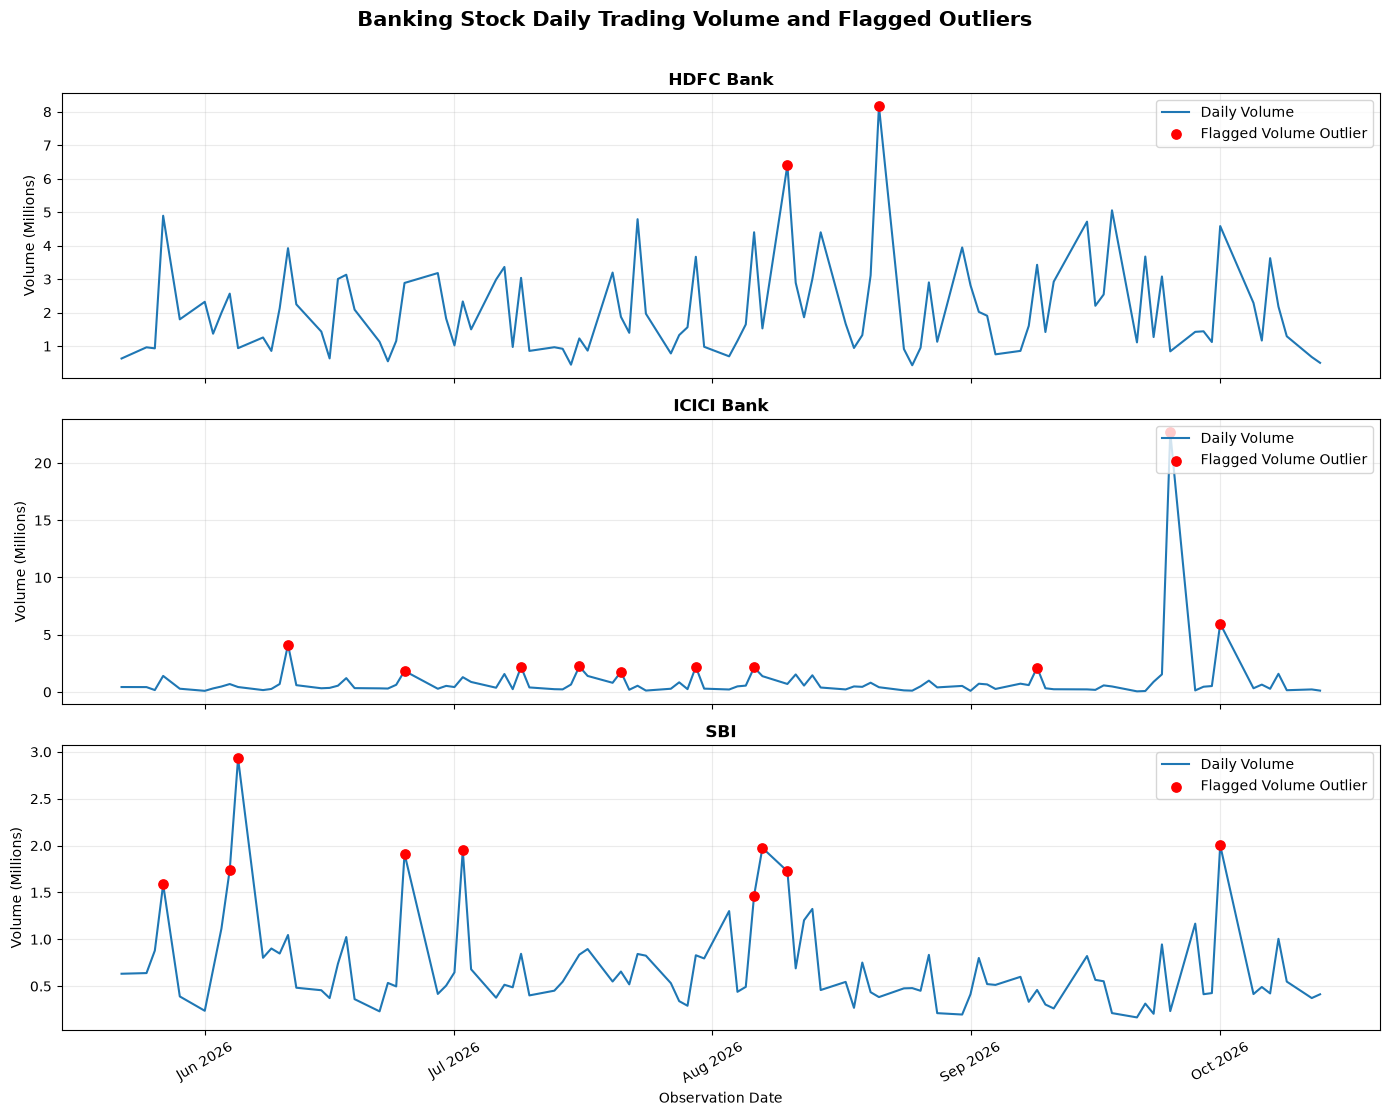

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\11_Banking_Stock_Daily_Volume_Outliers.png


In [29]:

# ============================================================
# VISUALIZATION 11: DAILY VOLUME WITH FLAGGED OUTLIERS
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 11),
    sharex=True
)

stock_order = [
    "HDFCBANK.BSE",
    "ICICIBANK.BSE",
    "SBIN.BSE"
]

stock_labels = {
    "HDFCBANK.BSE": "HDFC Bank",
    "ICICIBANK.BSE": "ICICI Bank",
    "SBIN.BSE": "SBI"
}

for ax, stock in zip(axes, stock_order):

    stock_data = volume_analysis[
        volume_analysis["stock_symbol"] == stock
    ]

    flagged = stock_data[
        stock_data["volume_outlier"]
    ]

    # Convert share counts into millions
    ax.plot(
        stock_data["observation_date"],
        stock_data["volume"] / 1_000_000,
        linewidth=1.5,
        label="Daily Volume"
    )

    # Highlight existing statistical outliers
    ax.scatter(
        flagged["observation_date"],
        flagged["volume"] / 1_000_000,
        color="red",
        s=45,
        zorder=3,
        label="Flagged Volume Outlier"
    )

    ax.set_title(
        stock_labels[stock],
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel("Volume (Millions)")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Observation Date")

axes[-1].xaxis.set_major_locator(
    mdates.MonthLocator()
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

fig.suptitle(
    "Banking Stock Daily Trading Volume and Flagged Outliers",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.xticks(rotation=30)
plt.tight_layout()

daily_volume_chart_path = (
    visualization_dir / "11_Banking_Stock_Daily_Volume_Outliers.png"
)

plt.savefig(
    daily_volume_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", daily_volume_chart_path)


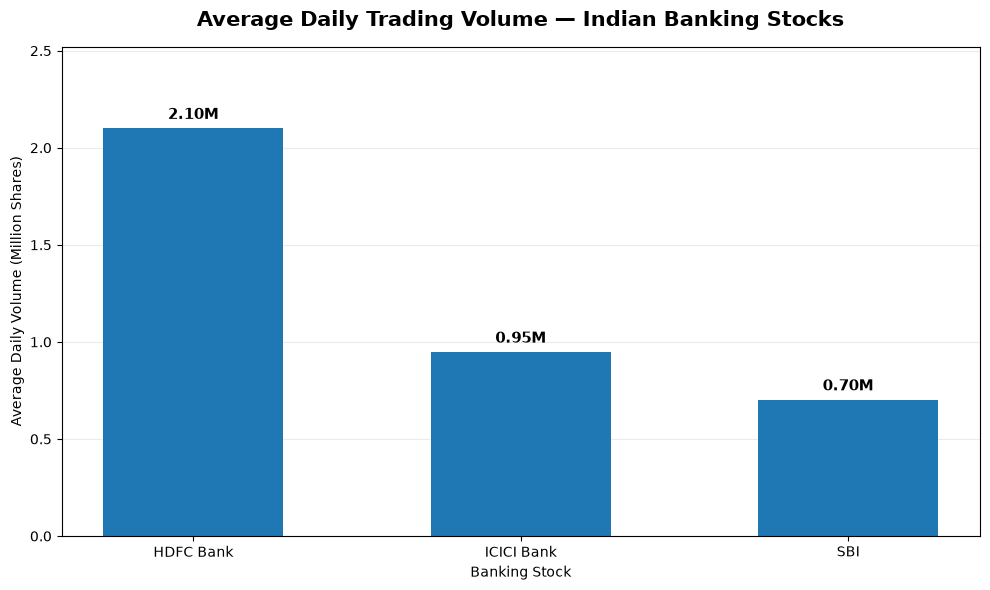

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\12_Banking_Stock_Average_Daily_Volume.png


In [30]:

# ============================================================
# VISUALIZATION 12: AVERAGE DAILY TRADING VOLUME
# ============================================================

avg_volume_millions = (
    volume_summary["avg_daily_volume"] / 1_000_000
)

display_labels = [
    stock_labels[symbol]
    for symbol in avg_volume_millions.index
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    display_labels,
    avg_volume_millions.values,
    width=0.55
)

for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.03,
        f"{height:.2f}M",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Average Daily Trading Volume — Indian Banking Stocks",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Banking Stock")
ax.set_ylabel("Average Daily Volume (Million Shares)")

ax.set_ylim(
    0,
    avg_volume_millions.max() * 1.2
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

avg_volume_chart_path = (
    visualization_dir / "12_Banking_Stock_Average_Daily_Volume.png"
)

plt.savefig(
    avg_volume_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", avg_volume_chart_path)


In [31]:

# ============================================================
# FLAGGED VOLUME OUTLIER REVIEW
# ============================================================

flagged_volume_records = volume_analysis.loc[
    volume_analysis["volume_outlier"],
    [
        "observation_date",
        "stock_symbol",
        "volume",
        "close_price",
        "volume_outlier"
    ]
].copy()

flagged_volume_records = (
    flagged_volume_records
    .sort_values(
        ["stock_symbol", "observation_date"]
    )
    .reset_index(drop=True)
)

assert len(flagged_volume_records) == 21

print("Flagged Volume Observations:")
display(flagged_volume_records)

print("\nFlagged observations by stock:")
print(
    flagged_volume_records["stock_symbol"].value_counts()
)


Flagged Volume Observations:


,observation_date,stock_symbol,volume,close_price,volume_outlier
0,2026-08-10,HDFCBANK.BSE,6406231,732.00,True
1,2026-08-21,HDFCBANK.BSE,8163779,727.50,True
2,2026-06-11,ICICIBANK.BSE,4128427,1317.40,True
3,2026-06-25,ICICIBANK.BSE,1838904,1387.90,True
4,2026-07-09,ICICIBANK.BSE,2193131,1381.60,True
5,2026-07-16,ICICIBANK.BSE,2227737,1418.20,True
6,2026-07-21,ICICIBANK.BSE,1758118,1462.95,True
7,2026-07-30,ICICIBANK.BSE,2194319,1436.50,True
8,2026-08-06,ICICIBANK.BSE,2137432,1476.95,True
9,2026-09-09,ICICIBANK.BSE,2129133,1390.10,True



Flagged observations by stock:
stock_symbol
ICICIBANK.BSE    10
SBIN.BSE          9
HDFCBANK.BSE      2
Name: count, dtype: int64



### Banking Stock Trading Volume — Business Findings

**Analysis Period:** May 22 – October 13, 2026

#### Average Daily Trading Volume

| Stock | Average Daily Volume |
|---|---:|
| HDFC Bank | 2,099,947 shares |
| ICICI Bank | 947,414 shares |
| SBI | 701,781 shares |

#### Flagged Statistical Volume Outliers

| Stock | Flagged Observations | Outlier Rate |
|---|---:|---:|
| HDFC Bank | 2 | 2.02% |
| ICICI Bank | 10 | 10.10% |
| SBI | 9 | 9.09% |

#### Key Findings

1. HDFC Bank recorded the highest average daily
   trading volume among the three stocks.

2. ICICI Bank recorded the largest number of flagged
   volume outliers, with 10 observations.

3. SBI recorded 9 flagged volume outliers.

4. HDFC Bank recorded only 2 flagged observations,
   despite having the highest average trading volume.

5. Statistical volume outliers were preserved
   throughout the analysis.

#### Business Implications

The stocks exhibited different historical trading
activity patterns.

Unusual trading volumes may justify further investigation
alongside price movements, corporate announcements,
and market-wide events.

However, the presence of a volume outlier alone
does not establish its cause.

#### Recommendations

- Monitor daily trading-volume trends.
- Review unusually high or low volume observations.
- Compare flagged dates with corresponding price changes.
- Investigate relevant company or market announcements
  before drawing conclusions.
- Retain the original observations for reproducibility.

#### Limitations

- IQR flags are statistical indicators, not confirmed
  trading anomalies or data errors.
- Trading volume alone does not measure market liquidity.
- Different share counts and trading characteristics
  affect comparisons across stocks.
- No external event investigation has been performed.



## 9. Banking Stock Return Correlation Analysis

### Business Question
How strongly are daily closing-price returns correlated
across HDFC Bank, ICICI Bank, and SBI?

### Business Objective
Measure historical linear co-movement between the
three banking stocks to support market intelligence
and diversification analysis.

### Methodology
1. Reuse the validated daily stock returns.
2. Verify that all 98 return dates are aligned.
3. Calculate the Pearson correlation matrix.
4. Reconcile pairwise correlations with PostgreSQL.
5. Create a correlation heatmap.
6. Create a pairwise correlation comparison chart.

### Interpretation
- Positive correlation: returns tend to move together.
- Negative correlation: returns tend to move oppositely.
- Correlation near zero: weak linear relationship.

### Limitations
- Correlation does not imply causation.
- Historical correlations may change over time.
- A short observation window limits generalization.
- Correlation does not independently measure risk.


In [32]:

# ============================================================
# STEP 7.9: BANKING STOCK RETURN CORRELATION
# ============================================================

# Verify aligned daily returns
assert stock_daily_returns.shape == (98, 3)
assert stock_daily_returns.isna().sum().sum() == 0

# Calculate Pearson correlation matrix
stock_correlation = stock_daily_returns.corr(
    method="pearson"
)

# Validate matrix
assert stock_correlation.shape == (3, 3)

assert np.allclose(
    stock_correlation.to_numpy(),
    stock_correlation.to_numpy().T
)

assert np.allclose(
    np.diag(stock_correlation),
    1.0
)

print("Banking stock correlation calculation: PASSED")

print("\nPearson Correlation Matrix:")
display(stock_correlation.round(4))


Banking stock correlation calculation: PASSED

Pearson Correlation Matrix:


stock_symbol,HDFCBANK.BSE,ICICIBANK.BSE,SBIN.BSE
stock_symbol,,,
HDFCBANK.BSE,1.0000,0.2295,0.3204
ICICIBANK.BSE,0.2295,1.0000,0.4874
SBIN.BSE,0.3204,0.4874,1.0000


In [33]:

# ============================================================
# VALIDATION: PYTHON VS POSTGRESQL
# ============================================================

expected_correlations = {
    ("ICICIBANK.BSE", "SBIN.BSE"): 0.4874,
    ("HDFCBANK.BSE", "SBIN.BSE"): 0.3204,
    ("HDFCBANK.BSE", "ICICIBANK.BSE"): 0.2295
}

for (stock_a, stock_b), expected in expected_correlations.items():

    actual = stock_correlation.loc[
        stock_a, stock_b
    ]

    assert np.isclose(
        actual,
        expected,
        atol=0.0001
    ), (
        f"Correlation mismatch: {stock_a} vs {stock_b}. "
        f"Python={actual:.6f}, SQL={expected:.4f}"
    )

print("Python vs PostgreSQL reconciliation: PASSED")
print("All three pairwise correlations match SQL.")


Python vs PostgreSQL reconciliation: PASSED
All three pairwise correlations match SQL.


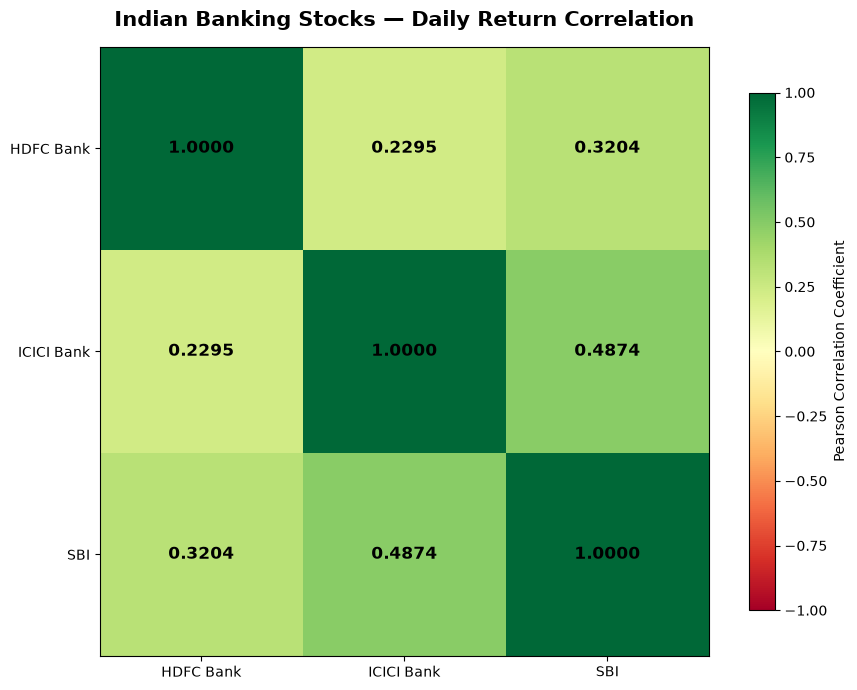

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\13_Banking_Stock_Correlation_Heatmap.png


In [34]:

# ============================================================
# VISUALIZATION 13: BANKING STOCK CORRELATION HEATMAP
# ============================================================

stock_order = [
    "HDFCBANK.BSE",
    "ICICIBANK.BSE",
    "SBIN.BSE"
]

stock_labels = [
    "HDFC Bank",
    "ICICI Bank",
    "SBI"
]

corr_matrix = stock_correlation.loc[
    stock_order,
    stock_order
]

fig, ax = plt.subplots(figsize=(9, 7))

heatmap = ax.imshow(
    corr_matrix.to_numpy(),
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

# Axis labels
ax.set_xticks(range(3))
ax.set_yticks(range(3))

ax.set_xticklabels(stock_labels)
ax.set_yticklabels(stock_labels)

# Annotate correlation values
for i in range(3):
    for j in range(3):

        value = corr_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.4f}",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="black"
        )

ax.set_title(
    "Indian Banking Stocks — Daily Return Correlation",
    fontsize=15,
    fontweight="bold",
    pad=15
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.85
)

colorbar.set_label(
    "Pearson Correlation Coefficient"
)

plt.tight_layout()

correlation_heatmap_path = (
    visualization_dir
    / "13_Banking_Stock_Correlation_Heatmap.png"
)

plt.savefig(
    correlation_heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", correlation_heatmap_path)


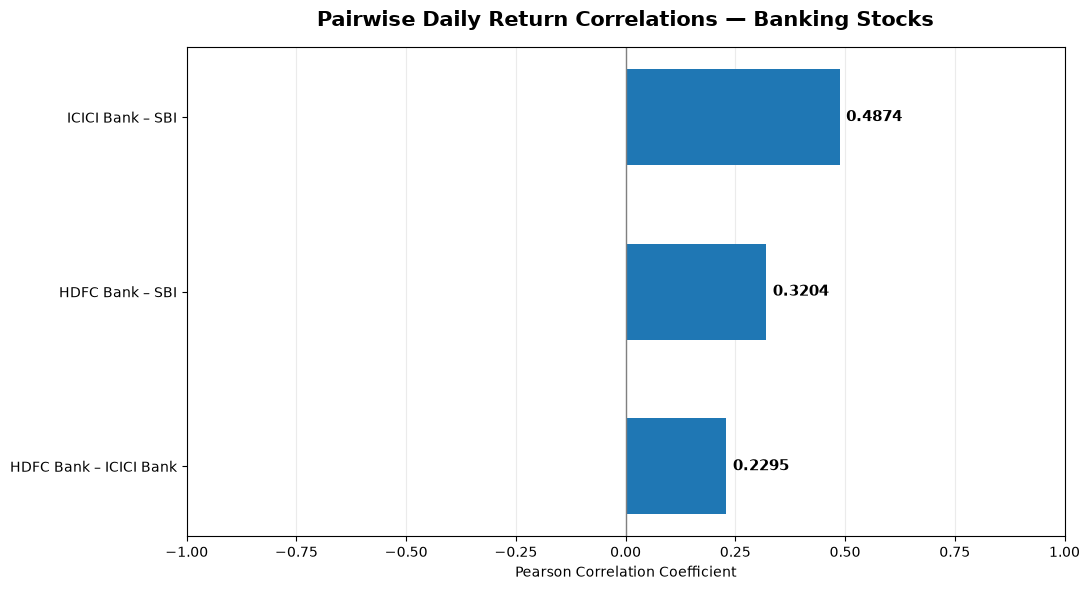

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\14_Banking_Stock_Pairwise_Correlations.png

Pairwise Correlation Summary:


,stock_pair,correlation
2,HDFC Bank – ICICI Bank,0.2295
1,HDFC Bank – SBI,0.3204
0,ICICI Bank – SBI,0.4874


In [35]:

# ============================================================
# VISUALIZATION 14: PAIRWISE STOCK CORRELATIONS
# ============================================================

correlation_pairs = pd.DataFrame({
    "stock_pair": [
        "ICICI Bank – SBI",
        "HDFC Bank – SBI",
        "HDFC Bank – ICICI Bank"
    ],
    "correlation": [
        stock_correlation.loc[
            "ICICIBANK.BSE", "SBIN.BSE"
        ],
        stock_correlation.loc[
            "HDFCBANK.BSE", "SBIN.BSE"
        ],
        stock_correlation.loc[
            "HDFCBANK.BSE", "ICICIBANK.BSE"
        ]
    ]
})

correlation_pairs = correlation_pairs.sort_values(
    "correlation",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    correlation_pairs["stock_pair"],
    correlation_pairs["correlation"],
    height=0.55
)

for bar in bars:

    value = bar.get_width()

    ax.text(
        value + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Pairwise Daily Return Correlations — Banking Stocks",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Pearson Correlation Coefficient")

# Full possible Pearson correlation range
ax.set_xlim(-1, 1)

ax.axvline(
    0,
    color="gray",
    linewidth=1
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

pairwise_correlation_chart_path = (
    visualization_dir
    / "14_Banking_Stock_Pairwise_Correlations.png"
)

plt.savefig(
    pairwise_correlation_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", pairwise_correlation_chart_path)

print("\nPairwise Correlation Summary:")
display(correlation_pairs.round(4))



### Banking Stock Correlation — Business Findings

**Analysis Period:** May 22 – October 13, 2026

#### Historical Pairwise Correlations

| Banking Stock Pair | Pearson Correlation |
|---|---:|
| ICICI Bank – SBI | 0.4874 |
| HDFC Bank – SBI | 0.3204 |
| HDFC Bank – ICICI Bank | 0.2295 |

#### Key Findings

1. ICICI Bank and SBI exhibited the strongest
   positive daily return correlation at 0.4874.

2. HDFC Bank and SBI showed a weaker positive
   correlation of 0.3204.

3. HDFC Bank and ICICI Bank exhibited the weakest
   positive correlation at 0.2295.

4. All three banking stock pairs demonstrated
   positive historical linear relationships.

5. None of the three stock pairs exhibited
   near-perfect positive correlation.

#### Business Implications

The three banking stocks did not move identically
during the historical analysis period.

The lower correlation between HDFC Bank and ICICI Bank
suggests weaker historical linear co-movement
compared with the other two pairs.

However, lower correlation alone does not guarantee
portfolio diversification benefits or reduced losses.

#### Recommendations

- Monitor return correlations over time.
- Compare correlation alongside volatility.
- Consider sector-wide events when interpreting
  co-movement.
- Avoid treating historical correlations as
  permanent relationships.

#### Limitations

- Correlation does not establish causation.
- Results are based on 98 aligned daily returns.
- The observation window is relatively short.
- Relationships may change during market stress.
- No portfolio optimization has been performed.


## 10. Banking Stock Historical Return-to-Volatility Analysis

### Business Question
Which banking stock demonstrated the strongest
historical average return relative to volatility?

### Business Objective
Compare the return and volatility characteristics
of HDFC Bank, ICICI Bank, and SBI using a consistent
descriptive performance measure.

### Methodology
1. Reuse the validated daily stock returns.
2. Calculate average daily percentage returns.
3. Annualize the arithmetic mean using 252.
4. Calculate annualized historical volatility.
5. Calculate the return-to-volatility ratio.
6. Rank stocks by the calculated ratio.
7. Reconcile all results with PostgreSQL.
8. Create two performance comparison visualizations.

### Calculations

Annualized Arithmetic Average Return (%) =
Average Daily Return (%) * 252

Annualized Volatility (%) =
Sample Standard Deviation of Daily Returns * sqrt(252)

Return-to-Volatility Ratio =
Annualized Arithmetic Average Return / Annualized Volatility

### Interpretation
A higher ratio indicates a higher historical arithmetic
average return relative to observed volatility.

The ratio is descriptive and is not a Sharpe ratio.

### Limitations
- No risk-free rate is subtracted.
- Arithmetic annualization is not compounded return.
- Returns exclude dividends and transaction costs.
- The historical period is relatively short.
- The metric does not predict future performance.


In [36]:

# ============================================================
# STEP 7.10: HISTORICAL RETURN-TO-VOLATILITY ANALYSIS
# ============================================================

# Annualization convention
TRADING_DAYS = 252

# Calculate annualized arithmetic average returns
annualized_avg_returns = (
    stock_daily_returns.mean() * TRADING_DAYS
)

# Calculate annualized historical volatility
annualized_stock_volatility = (
    stock_daily_returns.std(ddof=1)
    * np.sqrt(TRADING_DAYS)
)

# Prepare ranking DataFrame
stock_risk_return = pd.DataFrame({
    "price_return_pct":
        stock_performance["price_return_pct"],

    "annualized_avg_return_pct":
        annualized_avg_returns,

    "annualized_volatility_pct":
        annualized_stock_volatility
})

# Descriptive return-to-volatility ratio
stock_risk_return["return_volatility_ratio"] = (
    stock_risk_return["annualized_avg_return_pct"]
    / stock_risk_return["annualized_volatility_pct"]
)

# Rank stocks by ratio
stock_risk_return = (
    stock_risk_return
    .sort_values(
        "return_volatility_ratio",
        ascending=False
    )
)

stock_risk_return["performance_rank"] = range(
    1,
    len(stock_risk_return) + 1
)

stock_risk_return.index.name = "stock_symbol"

print("Banking Stock Historical Risk-Return Summary:")
display(stock_risk_return.round(4))


Banking Stock Historical Risk-Return Summary:


,price_return_pct,annualized_avg_return_pct,annualized_volatility_pct,return_volatility_ratio,performance_rank
stock_symbol,,,,,
ICICIBANK.BSE,7.5342,20.2436,17.7367,1.1413,1
SBIN.BSE,0.7165,3.5226,18.4617,0.1908,2
HDFCBANK.BSE,-6.8111,-15.7564,21.8859,-0.7199,3


In [37]:

# ============================================================
# VALIDATION: PYTHON VS POSTGRESQL
# ============================================================

expected_risk_return = {
    "ICICIBANK.BSE": {
        "price_return_pct": 7.53,
        "annualized_avg_return_pct": 20.24,
        "annualized_volatility_pct": 17.7367,
        "return_volatility_ratio": 1.1413,
        "performance_rank": 1
    },
    "SBIN.BSE": {
        "price_return_pct": 0.72,
        "annualized_avg_return_pct": 3.52,
        "annualized_volatility_pct": 18.4617,
        "return_volatility_ratio": 0.1908,
        "performance_rank": 2
    },
    "HDFCBANK.BSE": {
        "price_return_pct": -6.81,
        "annualized_avg_return_pct": -15.76,
        "annualized_volatility_pct": 21.8859,
        "return_volatility_ratio": -0.7199,
        "performance_rank": 3
    }
}

# SQL values are rounded, so use metric-specific
# tolerances for comparison.
tolerances = {
    "price_return_pct": 0.01,
    "annualized_avg_return_pct": 0.01,
    "annualized_volatility_pct": 0.0001,
    "return_volatility_ratio": 0.0001
}

for stock, metrics in expected_risk_return.items():

    for metric, expected in metrics.items():

        actual = stock_risk_return.loc[stock, metric]

        if metric == "performance_rank":
            assert actual == expected
        else:
            assert np.isclose(
                actual,
                expected,
                atol=tolerances[metric],
                rtol=0
            ), (
                f"Mismatch: {stock} | {metric} | "
                f"Python={actual:.6f} | SQL={expected}"
            )

print("Python vs PostgreSQL reconciliation: PASSED")
print("All historical risk-return metrics match SQL.")


Python vs PostgreSQL reconciliation: PASSED
All historical risk-return metrics match SQL.


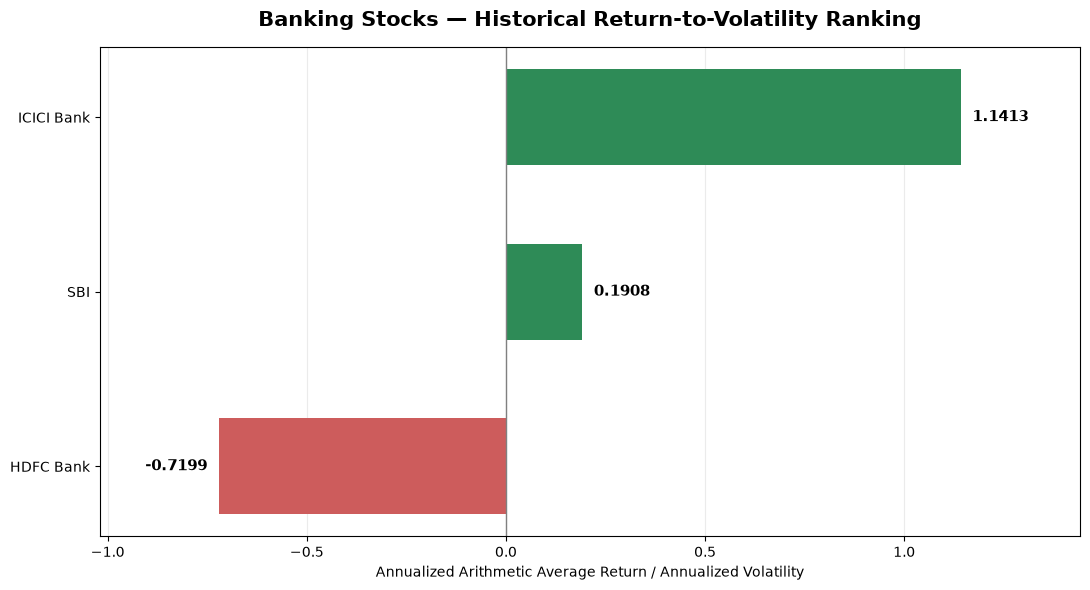

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\15_Banking_Stock_Return_Volatility_Ranking.png


In [38]:

# ============================================================
# VISUALIZATION 15: RETURN-TO-VOLATILITY RANKING
# ============================================================

stock_labels = {
    "HDFCBANK.BSE": "HDFC Bank",
    "ICICIBANK.BSE": "ICICI Bank",
    "SBIN.BSE": "SBI"
}

ranking_chart = stock_risk_return.sort_values(
    "return_volatility_ratio",
    ascending=True
)

labels = [
    stock_labels[symbol]
    for symbol in ranking_chart.index
]

values = ranking_chart[
    "return_volatility_ratio"
]

colors = [
    "seagreen" if value >= 0 else "indianred"
    for value in values
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    labels,
    values,
    color=colors,
    height=0.55
)

# Add ratio labels
for bar in bars:

    value = bar.get_width()

    offset = 0.03 if value >= 0 else -0.03

    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.axvline(
    0,
    color="gray",
    linewidth=1
)

ax.set_title(
    "Banking Stocks — Historical Return-to-Volatility Ranking",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Annualized Arithmetic Average Return / Annualized Volatility"
)

ax.set_xlim(
    values.min() - 0.3,
    values.max() + 0.3
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

ranking_chart_path = (
    visualization_dir
    / "15_Banking_Stock_Return_Volatility_Ranking.png"
)

plt.savefig(
    ranking_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", ranking_chart_path)


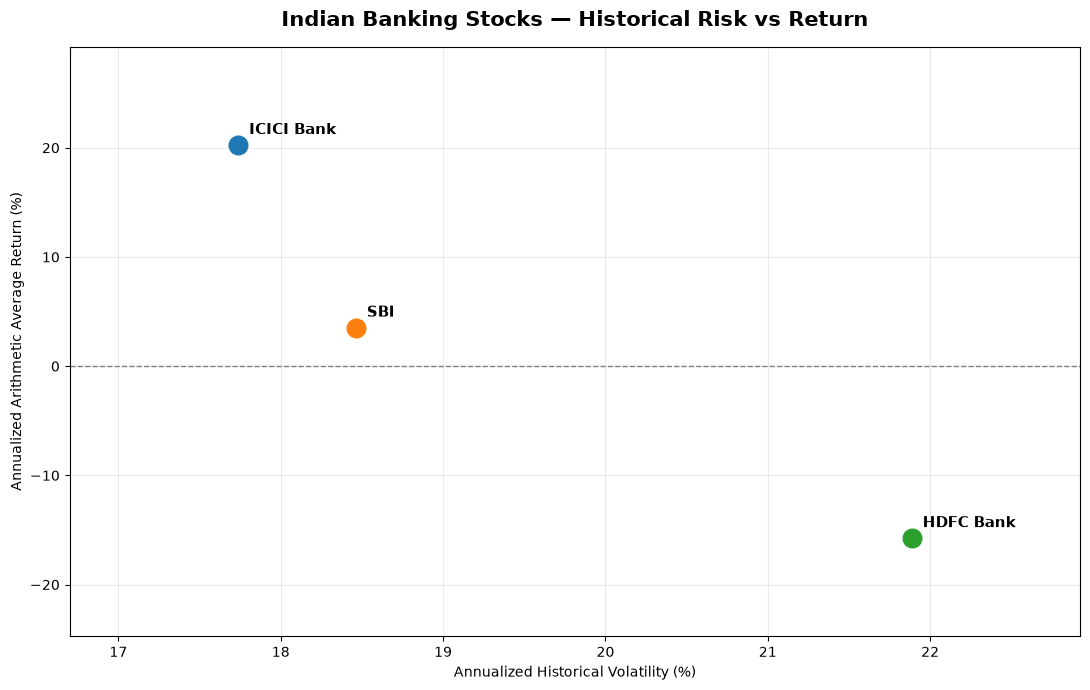

Chart saved: E:\BA Projects\Financial_Market_Intelligence_Analytics\Python\Visualizations\16_Banking_Stock_Risk_Return_Comparison.png


In [39]:

# ============================================================
# VISUALIZATION 16: HISTORICAL RISK VS RETURN
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

for symbol, row in stock_risk_return.iterrows():

    ax.scatter(
        row["annualized_volatility_pct"],
        row["annualized_avg_return_pct"],
        s=180,
        zorder=3
    )

    ax.annotate(
        stock_labels[symbol],
        (
            row["annualized_volatility_pct"],
            row["annualized_avg_return_pct"]
        ),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )

ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Indian Banking Stocks — Historical Risk vs Return",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Annualized Historical Volatility (%)")
ax.set_ylabel("Annualized Arithmetic Average Return (%)")

ax.grid(alpha=0.25)

# Add space around the plotted points
ax.margins(x=0.25, y=0.25)

plt.tight_layout()

risk_return_chart_path = (
    visualization_dir
    / "16_Banking_Stock_Risk_Return_Comparison.png"
)

plt.savefig(
    risk_return_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", risk_return_chart_path)



### Banking Stock Historical Return-to-Volatility Findings

**Analysis Period:** May 22 – October 13, 2026

#### Historical Performance Ranking

| Rank | Stock | Return-to-Volatility Ratio |
|---|---|---:|
| 1 | ICICI Bank | 1.1413 |
| 2 | SBI | 0.1908 |
| 3 | HDFC Bank | -0.7199 |

#### Key Findings

1. ICICI Bank recorded the highest historical
   return-to-volatility ratio at approximately 1.1413.

2. SBI recorded a positive but substantially lower
   ratio of approximately 0.1908.

3. HDFC Bank recorded a negative ratio of approximately
   -0.7199, reflecting its negative annualized arithmetic
   average return during the observation period.

4. ICICI Bank also had the highest historical
   closing-price return and the lowest annualized
   volatility among the three stocks.

5. HDFC Bank had the lowest historical closing-price
   return and the highest annualized volatility.

#### Business Implications

The three banks demonstrated different historical
risk-return characteristics despite belonging to
the same industry.

The results help compare observed market behavior,
but they should not be interpreted as forecasts
or standalone investment recommendations.

#### Recommendations

- Compare returns and volatility together.
- Monitor changes in risk-return rankings over time.
- Include trading-volume and correlation analysis.
- Distinguish arithmetic annualization from
  realized holding-period returns.
- Avoid making investment decisions using one
  descriptive metric alone.

#### Limitations

- This is not a Sharpe ratio.
- No risk-free rate is included.
- Annualized arithmetic returns are not compounded.
- Historical returns exclude dividends and costs.
- The analysis period is relatively short.
- Historical rankings may not persist.



## 11. Power BI-Ready Financial Data Preparation

### Business Objective
Create validated, reproducible analytical datasets
for the final Financial Market Intelligence dashboard.

### Data Sources
- PostgreSQL: public.fx_rates
- PostgreSQL: public.banking_stocks
- Python financial metrics calculated in Phase 7

### Output Design
FX module:
1. Daily FX analytics
2. Currency exposure and stress scenarios
3. Currency performance and volatility summary

Banking stock module:
4. Daily stock analytics
5. Stock performance and risk summary
6. Pairwise return correlations

### Data Modeling Principles
- Preserve validated source observations.
- Maintain explicit business keys.
- Keep daily observations separate from summaries.
- Include outlier flags for transparent review.
- Preserve dates as ISO-formatted values.
- Avoid mixing currency amounts with percentage metrics.
- Export reproducible CSV files.

### Validation Requirements
Verify:
- Expected row counts
- Unique business keys
- No unexpected missing values
- Financial metric reconciliation
- Successful file creation

### Important Assumptions
Import invoices and stress scenarios are hypothetical.

Stock performance metrics are historical and do not
represent investment recommendations.


In [40]:

# ============================================================
# STEP 7.11: POWER BI DATA EXPORT SETUP
# ============================================================

powerbi_data_dir = (
    project_root / "Data" / "processed" / "PowerBI"
)

powerbi_data_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Power BI export directory:")
print(powerbi_data_dir)


Power BI export directory:
E:\BA Projects\Financial_Market_Intelligence_Analytics\Data\processed\PowerBI


In [41]:

# ============================================================
# EXPORT 1: DAILY FX ANALYTICS
# ============================================================

fx_daily_export = fx_df.copy()

fx_daily_export = fx_daily_export.sort_values(
    ["base_currency", "quote_currency", "observation_date"]
).reset_index(drop=True)

fx_daily_export["currency_pair"] = (
    fx_daily_export["base_currency"]
    + "/"
    + fx_daily_export["quote_currency"]
)

fx_daily_export["daily_return_pct"] = (
    fx_daily_export
    .groupby("currency_pair")["exchange_rate"]
    .pct_change(fill_method=None) * 100
)

# Preserve first-observation missing returns
assert len(fx_daily_export) == 312
assert fx_daily_export["daily_return_pct"].isna().sum() == 3

assert not fx_daily_export.duplicated(
    ["observation_date", "currency_pair"]
).any()

print("Daily FX export prepared:", fx_daily_export.shape)
display(fx_daily_export.head())


Daily FX export prepared: (312, 8)


,observation_date,base_currency,quote_currency,exchange_rate,source,is_outlier,currency_pair,daily_return_pct
0,2026-05-21,EUR,INR,111.5885,Frankfurter,False,EUR/INR,NaN
1,2026-05-22,EUR,INR,110.9585,Frankfurter,False,EUR/INR,-0.564574
2,2026-05-25,EUR,INR,110.8870,Frankfurter,False,EUR/INR,-0.064439
3,2026-05-26,EUR,INR,111.3200,Frankfurter,False,EUR/INR,0.390488
4,2026-05-27,EUR,INR,111.3650,Frankfurter,False,EUR/INR,0.040424


In [42]:

# ============================================================
# EXPORT 2: FX CURRENCY SUMMARY
# ============================================================

fx_currency_summary = pd.DataFrame({
    "currency_pair": fx_pivot.columns,
    "opening_rate": fx_pivot.iloc[0].values,
    "closing_rate": fx_pivot.iloc[-1].values
})

fx_currency_summary["price_change_pct"] = (
    (
        fx_currency_summary["closing_rate"]
        / fx_currency_summary["opening_rate"]
    ) - 1
) * 100

fx_currency_summary["annualized_volatility_pct"] = (
    fx_currency_summary["currency_pair"]
    .map(
        fx_volatility_summary[
            "annualized_volatility_pct"
        ]
    )
)

fx_currency_summary["avg_daily_return_pct"] = (
    fx_currency_summary["currency_pair"]
    .map(
        fx_volatility_summary[
            "avg_daily_return_pct"
        ]
    )
)

assert len(fx_currency_summary) == 3
assert fx_currency_summary.isna().sum().sum() == 0

print("FX currency summary prepared:")
display(fx_currency_summary.round(4))


FX currency summary prepared:


,currency_pair,opening_rate,closing_rate,price_change_pct,annualized_volatility_pct,avg_daily_return_pct
0,EUR/INR,111.5885,106.60,-4.4704,5.8938,-0.0437
1,GBP/INR,129.1100,126.21,-2.2461,6.1332,-0.0213
2,USD/INR,96.2100,95.28,-0.9666,4.9279,-0.0090


In [43]:

# ============================================================
# EXPORT 3: FX EXPOSURE SCENARIOS
# ============================================================

scenario_frames = []

for scenario_pct in [0, 2, 5]:

    scenario_df = import_exposure[
        [
            "currency",
            "invoice_amount",
            "rate_date",
            "current_rate",
            "current_inr_exposure"
        ]
    ].copy()

    scenario_df["scenario_pct"] = scenario_pct

    scenario_df["stressed_inr_cost"] = (
        scenario_df["current_inr_exposure"]
        * (1 + scenario_pct / 100)
    )

    scenario_df["additional_inr_cost"] = (
        scenario_df["stressed_inr_cost"]
        - scenario_df["current_inr_exposure"]
    )

    scenario_frames.append(scenario_df)

fx_exposure_scenarios = pd.concat(
    scenario_frames,
    ignore_index=True
)

fx_exposure_scenarios = fx_exposure_scenarios.sort_values(
    ["currency", "scenario_pct"]
).reset_index(drop=True)

assert len(fx_exposure_scenarios) == 9

assert not fx_exposure_scenarios.duplicated(
    ["currency", "scenario_pct"]
).any()

assert np.isclose(
    fx_exposure_scenarios.loc[
        fx_exposure_scenarios["scenario_pct"] == 5,
        "additional_inr_cost"
    ].sum(),
    1640450,
    atol=0.01
)

print("FX exposure scenarios prepared:")
display(fx_exposure_scenarios.round(2))


FX exposure scenarios prepared:


C:\Users\Dell\AppData\Local\Temp\ipykernel_26632\2860154427.py:58: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(fx_exposure_scenarios.round(2))


,currency,invoice_amount,rate_date,current_rate,current_inr_exposure,scenario_pct,stressed_inr_cost,additional_inr_cost
0,EUR,100000,2026-10-13,106.60,10660000.0,0,10660000.0,0.0
1,EUR,100000,2026-10-13,106.60,10660000.0,2,10873200.0,213200.0
2,EUR,100000,2026-10-13,106.60,10660000.0,5,11193000.0,533000.0
3,GBP,100000,2026-10-13,126.21,12621000.0,0,12621000.0,0.0
4,GBP,100000,2026-10-13,126.21,12621000.0,2,12873420.0,252420.0
5,GBP,100000,2026-10-13,126.21,12621000.0,5,13252050.0,631050.0
6,USD,100000,2026-10-13,95.28,9528000.0,0,9528000.0,0.0
7,USD,100000,2026-10-13,95.28,9528000.0,2,9718560.0,190560.0
8,USD,100000,2026-10-13,95.28,9528000.0,5,10004400.0,476400.0


In [44]:

# ============================================================
# EXPORT 4: DAILY BANKING STOCK ANALYTICS
# ============================================================

stock_daily_export = stocks_df.copy()

stock_daily_export = stock_daily_export.sort_values(
    ["stock_symbol", "observation_date"]
).reset_index(drop=True)

stock_daily_export["daily_return_pct"] = (
    stock_daily_export
    .groupby("stock_symbol")["close_price"]
    .pct_change(fill_method=None) * 100
)

assert len(stock_daily_export) == 297
assert stock_daily_export["daily_return_pct"].isna().sum() == 3

assert not stock_daily_export.duplicated(
    ["observation_date", "stock_symbol"]
).any()

print("Daily banking stock export prepared:")
display(stock_daily_export.head())


Daily banking stock export prepared:


,observation_date,stock_symbol,open_price,high_price,low_price,close_price,volume,source,price_outlier,volume_outlier,is_outlier,daily_return_pct
0,2026-05-22,HDFCBANK.BSE,759.00,774.90,759.00,766.40,629420,Alpha Vantage,False,False,False,NaN
1,2026-05-25,HDFCBANK.BSE,778.00,788.00,775.25,786.85,964192,Alpha Vantage,False,False,False,2.668319
2,2026-05-26,HDFCBANK.BSE,785.95,790.90,777.00,779.00,932064,Alpha Vantage,False,False,False,-0.997649
3,2026-05-27,HDFCBANK.BSE,772.10,772.10,756.60,758.50,4893862,Alpha Vantage,False,False,False,-2.631579
4,2026-05-29,HDFCBANK.BSE,749.00,760.65,738.10,744.75,1799471,Alpha Vantage,False,False,False,-1.812788


In [45]:

# ============================================================
# EXPORT 5: BANKING STOCK PERFORMANCE SUMMARY
# ============================================================

stock_performance_summary = (
    stock_risk_return.reset_index().copy()
)

# Add trading volume metrics
stock_performance_summary = (
    stock_performance_summary.merge(
        volume_summary[
            [
                "avg_daily_volume",
                "total_volume",
                "volume_outliers",
                "outlier_rate_pct"
            ]
        ].reset_index(),
        on="stock_symbol",
        how="left",
        validate="one_to_one"
    )
)

# Add opening and closing prices
stock_performance_summary = (
    stock_performance_summary.merge(
        stock_performance[
            [
                "opening_close_price",
                "latest_close_price"
            ]
        ].reset_index(),
        on="stock_symbol",
        how="left",
        validate="one_to_one"
    )
)

assert len(stock_performance_summary) == 3
assert stock_performance_summary.isna().sum().sum() == 0

print("Banking stock performance summary prepared:")
display(stock_performance_summary.round(4))


Banking stock performance summary prepared:


,stock_symbol,price_return_pct,annualized_avg_return_pct,annualized_volatility_pct,return_volatility_ratio,performance_rank,avg_daily_volume,total_volume,volume_outliers,outlier_rate_pct,opening_close_price,latest_close_price
0,ICICIBANK.BSE,7.5342,20.2436,17.7367,1.1413,1,9.474141e+05,93793998,10,10.1010,1264.9,1360.2
1,SBIN.BSE,0.7165,3.5226,18.4617,0.1908,2,7.017809e+05,69476314,9,9.0909,949.1,955.9
2,HDFCBANK.BSE,-6.8111,-15.7564,21.8859,-0.7199,3,2.099947e+06,207894787,2,2.0202,766.4,714.2


In [46]:

# ============================================================
# EXPORT 6: BANKING STOCK CORRELATIONS
# ============================================================

stock_correlations = pd.DataFrame({
    "stock_a": [
        "ICICIBANK.BSE",
        "HDFCBANK.BSE",
        "HDFCBANK.BSE"
    ],
    "stock_b": [
        "SBIN.BSE",
        "SBIN.BSE",
        "ICICIBANK.BSE"
    ]
})

stock_correlations["pearson_correlation"] = (
    stock_correlations.apply(
        lambda row: stock_correlation.loc[
            row["stock_a"],
            row["stock_b"]
        ],
        axis=1
    )
)

assert len(stock_correlations) == 3
assert stock_correlations.isna().sum().sum() == 0

print("Stock correlations prepared:")
display(stock_correlations.round(4))


Stock correlations prepared:


,stock_a,stock_b,pearson_correlation
0,ICICIBANK.BSE,SBIN.BSE,0.4874
1,HDFCBANK.BSE,SBIN.BSE,0.3204
2,HDFCBANK.BSE,ICICIBANK.BSE,0.2295


In [47]:

# ============================================================
# FINAL POWER BI EXPORT VALIDATION
# ============================================================

export_manifest = {
    "fx_daily_analytics.csv": {
        "data": fx_daily_export,
        "rows": 312,
        "keys": ["observation_date", "currency_pair"]
    },
    "fx_currency_summary.csv": {
        "data": fx_currency_summary,
        "rows": 3,
        "keys": ["currency_pair"]
    },
    "fx_exposure_scenarios.csv": {
        "data": fx_exposure_scenarios,
        "rows": 9,
        "keys": ["currency", "scenario_pct"]
    },
    "stock_daily_analytics.csv": {
        "data": stock_daily_export,
        "rows": 297,
        "keys": ["observation_date", "stock_symbol"]
    },
    "stock_performance_summary.csv": {
        "data": stock_performance_summary,
        "rows": 3,
        "keys": ["stock_symbol"]
    },
    "stock_correlations.csv": {
        "data": stock_correlations,
        "rows": 3,
        "keys": ["stock_a", "stock_b"]
    }
}

for filename, config in export_manifest.items():

    df = config["data"]

    assert len(df) == config["rows"], (
        f"Unexpected row count: {filename}"
    )

    assert not df.duplicated(
        config["keys"]
    ).any(), (
        f"Duplicate business keys: {filename}"
    )

    # First daily return per instrument is intentionally null.
    allowed_missing = (
        filename in {
            "fx_daily_analytics.csv",
            "stock_daily_analytics.csv"
        }
    )

    if allowed_missing:
        missing_columns = df.columns[
            df.isna().any()
        ].tolist()

        assert missing_columns == ["daily_return_pct"], (
            f"Unexpected missing columns: {filename}"
        )

        assert df["daily_return_pct"].isna().sum() == 3

    else:
        assert df.isna().sum().sum() == 0, (
            f"Unexpected missing values: {filename}"
        )

    # Export ISO-formatted dates to CSV
    export_df = df.copy()

    for column in export_df.select_dtypes(
        include=["datetime64[ns]", "datetimetz"]
    ).columns:
        export_df[column] = (
            export_df[column].dt.strftime("%Y-%m-%d")
        )

    output_path = powerbi_data_dir / filename

    export_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    # Verify the saved file exists
    assert output_path.is_file()

    print(
        f"PASSED | {filename} | "
        f"{len(df)} rows"
    )

print("\nAll six Power BI datasets exported successfully.")


PASSED | fx_daily_analytics.csv | 312 rows
PASSED | fx_currency_summary.csv | 3 rows
PASSED | fx_exposure_scenarios.csv | 9 rows
PASSED | stock_daily_analytics.csv | 297 rows
PASSED | stock_performance_summary.csv | 3 rows
PASSED | stock_correlations.csv | 3 rows

All six Power BI datasets exported successfully.
